## Аппроксимация рисунка без самопересечений на плоскости с помощью ряда Фурье

**Постановка задачи.** Задан рисунок на плоскости, нарисованный одним росчерком, без самопересечений. Нужно аппроксимировать его рядом Фурье, подбирая параметры:
1. последовательно;
2. последовательно, с дообучением параметров ранее добавленных компонент;
3. задав число компонент и обучив все параметры сразу.

Сравнить и проанализировать подходы.

**Цель:** сравнить три способа подбора и объяснить, когда и почему они дают разный результат.

**План ноутбука.**
1. Ряд Фурье и эпициклы — как сумма вращающихся векторов рисует кривую.
2. Дискретный случай — ДПФ по точкам.
3. Данные — отладочная звезда и свой рисунок (буква M), равномерная сетка по длине.
4. Приближение $M$ векторами — качество, спектр, симметрия, эпициклы.
5. Теория: почему на равномерной сетке три подхода совпадают.
6. Эксперимент A: фиксированные целые частоты на равномерной и неравномерной сетке.
7. Теория: обучаемые частоты и невыпуклость.
8. Эксперимент B: обучаемые частоты.
9. Другие рисунки: галерея контуров.
10. Выводы.

In [99]:
import matplotlib.pyplot as plt
import numpy as np
import os; os.makedirs("figs", exist_ok=True)
import svgpathtools as svgtools
import pandas as pd

### 1. Ряд Фурье и эпициклы

Рисунок - это путь, по которому идет перо. Обозначим через $t \in [0, 1)$ "время" и запишем положение пера одним комплексным числом:
$$z(t) = x(t) + i y(t)$$

Нам важны следующие свойства кривой:

**Замкнутость.** Ряд Фурье описывает **периодические** функции: $z(t + 1) = z(t)$, значит перо в момент $t = 1$, должно вернуться в начало - кривая должна быть **замкнутой**. Что делать с незамкнутыми кривами - разберем позже.

**Параметризация.** Одну и ту же кривую можно пройти с разной скоростью: быстро на прямых участка и медленно на поворотах или равномерно. Стандартный выбор - **по длине дуги**: момент $t$ равен доле уже пройденной длины. Тогда перо двигается с постоянной скоростью, а точки при равных шагах по $t$ равномерно лежат на кривой. Почему это важно, также станет ясно позднее.

Для периодической $z(t)$ с периодом 1 мы знаем ее разложение в ряд Фурье:
$$z(t) = \sum_{k = -\infty}^{\infty}c_k e^{2 \pi i k t}, \quad c_k = \int_{0}^{1}z(t) e^{-2 \pi i k t}dt$$
То есть любую (достаточно хорошую) замкнутую кривую можно получить, складывая вращающиеся векторы: вектор $c_0$ стоит на месте, $c_1 e^{2 \pi i t}$ делает один оборот против часовой, $c_{-1} e^{-2 \pi i t}$ - один оборот по часовой и так далее.

Если приставим векторы друг к другу "хвост к голове", конец последнего будет рисовать кривую. Это есть **эпициклы**.

- $|c_k|$ - радиус $k$-го круга
- $\arg c_k$ - начальный угол вектора
- $c_0 = \int_{0}^{1} z(t) dt$ - среднее значение, то есть центр масс кривой (при равномерной параметризации)

_Пример._
Возьмем $z(t) = 1 \cdot e^{2 \pi i t} + 0.4 e^{-2 \pi i t}$. Распишем:
$$z(t) = (\cos 2 \pi t + i \sin 2 \pi t) + 0.4 (\cos 2 \pi t - i \sin 2 \pi t) = 1.4 \cos 2 \pi t + i 0.6 \sin 2 \pi t$$
Это эллипс с полуосями 1.4 и 0.6. Два вектора, вращающиеся навстречу друг другу: когда они сонаправлены, длины складываются, когда противоположны - вычитаются.

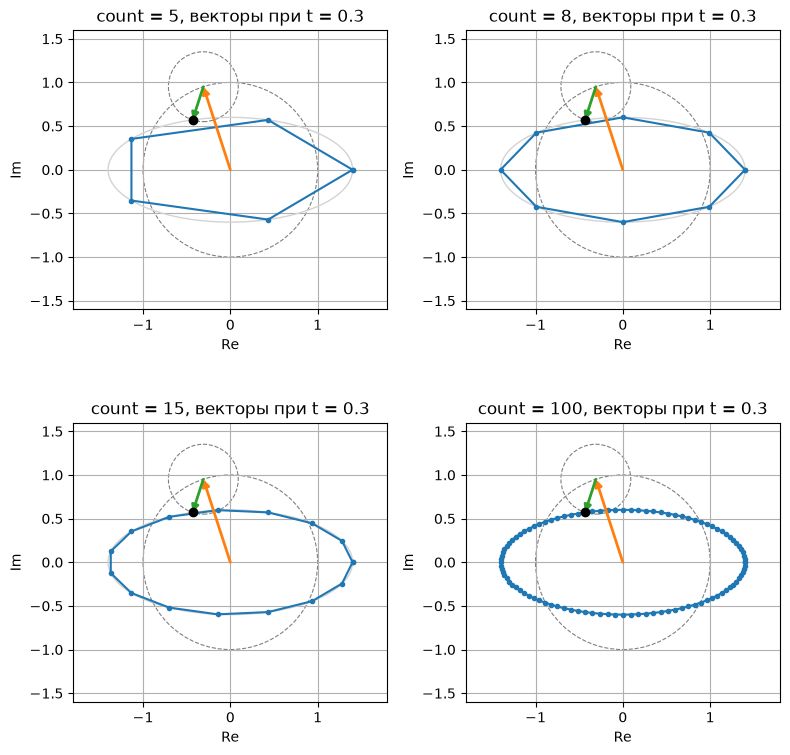

In [100]:
coeffs = [1.0, 0.4]
freqs  = [1, -1]

def get_ellipse(count, coeffs=coeffs, freqs=freqs):
    """Точки эллипса z(t) = sum c_k e^{2πikt} в count равномерных моментах t."""
    t = np.linspace(0, 1, count, endpoint=False)
    z = sum(c * np.exp(2j * np.pi * k * t) for c, k in zip(coeffs, freqs))
    return t, z

def draw_vectors(ax, coeffs, freqs, t0):
    """Цепочка векторов c_k e^{2πi k t0}, приставленных хвост к голове."""
    p = 0j
    for j, (c, k) in enumerate(zip(coeffs, freqs)):
        v = c * np.exp(2j * np.pi * k * t0)
        ax.add_patch(plt.Circle((p.real, p.imag), abs(c), fill=False, ls="--", lw=0.8, color="gray"))
        ax.annotate("", xy=((p + v).real, (p + v).imag), xytext=(p.real, p.imag),
                    arrowprops=dict(arrowstyle="-|>", color=f"C{j + 1}", lw=2, shrinkA=0, shrinkB=0))
        p += v
    ax.plot(p.real, p.imag, "o", color="black", ms=6, zorder=5)
    return p

counts = [5, 8, 15, 100]
t0 = 0.3

_, z_true = get_ellipse(400)
z_true = np.append(z_true, z_true[0])

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
for ax, count in zip(axes.flatten(), counts):
    ax.plot(z_true.real, z_true.imag, color="lightgray", lw=1)
    t, z = get_ellipse(count)
    z_closed = np.append(z, z[0])
    ax.plot(z_closed.real, z_closed.imag, marker=".", color="tab:blue")
    draw_vectors(ax, coeffs, freqs, t0)
    ax.set_title(f"count = {count}, векторы при t = {t0}")
    ax.set_xlabel("Re"); ax.set_ylabel("Im")
    ax.set_aspect("equal"); ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.6, 1.6)
    ax.grid(True)
plt.tight_layout()
plt.show()

Видно, что конец цепочки векторов (черная точка) лежит на настоящем эллипсе при любом `count`. При малом `count` получившаяся кривая - грубое приближение эллипса.

### 2. Дискретный случай

Компьютер представляет кривую как набор из $N$ точек $z_0, \dots, z_{N - 1}$, взятых в моменты $t_n = n / N$. 
В этом случае интеграл в поиске $c_k$ заменяется суммой:
$$c_k \approx \frac{1}{N} \sum_{n=0}^{N-1} z_n\, e^{-2\pi i k n / N}$$
Это **дискретное преобразование Фурье** (ДПФ), деленное на $N$. 

Понадобится свойство **дискретной ортогональности**. Векторы $a_k = (e^{\frac{2 \pi k n}{N}})_{n = 0}^{N - 1} \in \mathbb{C}^N$ при разных $k \in \{0, \dots, N - 1\}$ ортогональны, и $\lVert x \rVert^2 = N$:
$$\langle a_k, a_m \rangle = \sum_{n = 0}^{N - 1} e^{\frac{2 \pi i (k - m)n}{N}} = \begin{cases}
    N, & k \equiv m \pmod N \\
    0, & иначе
    \end{cases}
$$

Дискретные гармоники ортогональны: векторы $q_n = e^{\frac{2 \pi (k - m)n}{N}}$ - вершины правильного многоугольника на единичной окружности, а их сумма - замкнутый многоугольник, то есть ноль.

Убедимся на эллипсе, что ДПФ работает.

Например, для $N = 8$ получим следующие коэффициенты и частоты, им соответствующие:

In [101]:
t, z = get_ellipse(8)
N = len(z)

c = np.fft.fft(z) / N
k = np.fft.fftfreq(N, d=1/N).astype(int)

for kk, cc in zip(k, c):
    print(f"k = {kk:3d}   c_k = {np.round(cc, 10)}")

k =   0   c_k = (-0-0j)
k =   1   c_k = (1-0j)
k =   2   c_k = 0j
k =   3   c_k = (-0-0j)
k =  -4   c_k = 0j
k =  -3   c_k = (-0+0j)
k =  -2   c_k = -0j
k =  -1   c_k = (0.4+0j)


Видим, что ненулевые компоненты действительно получились только $c_{1} = 1, c_{-1} = 0.4$.

Несколько тонкостей:
- `np.fft.fft` **не делит на** $N$
- порядок частот при выходе: $0, 1, 2, \dots, \frac{N}{2} - 1, -\frac{N}{2}, \dots, -1$, поэтому используем `np.fft.fftfreq`
- точки берутся без дубля $t = 1$ (`endpoint=False`), иначе коэффициенты получатся неточные

### 3. Данные

Чтобы проверять методы, нужны кривые, заданные набором точек. Сначала возьмем кривую, для которой мы знаем ответ. Позже будем работать с настоящими рисунками.

В качестве примера возьмем $p$-лучевую звезду, то есть звезду с $2p$ вершинами, каждая из которых задается радиус-вектором $z_m = \rho_m e^{\frac{i \pi m}{p}} (m = 0, 1, \dots, 2p - 1)$, где $\rho_m$ чередуется: $R$ для лучей, $r$ для впадин.

Она, очевидно, замкнута, у нее есть углы, а значит коэффициенты Фурье убывают не мгновенно, как у эллипса, и есть, что приближать.

Она симметрична, поэтому спектр заранее известен: ненулевые компоненты только при $k \equiv 1 \pmod p$ при условиях:
- точки равномерны распределены по длиине
- обход начинается с вершины
- $N$ делится на $p$, чтобы поворот $\frac{2\pi}{p}$ переводил точки сетки ровно в точки сетки.

Чтобы симметрия сохранялась и в дискретном виде, возьмем $N$ кратное $p$, например $N = 1000$, $p = 5$.

In [102]:
def star(p=5, R=1.0, r=0.45):
    """Вершины p-лучевой звезды: 2p комплексных чисел, обход против часовой."""
    m = np.arange(2 * p)
    rho = np.where(m % 2 == 0, R, r)
    return rho * np.exp(1j * np.pi * m / p)

У звезды всего $2p$ вершин, а между ними отрезки. Чтобы ДПФ описывал именно эту ломаную, нужно много точек на ней - $N$ штук. Причем точки должны стоять **равномерно по длине**: тогда $t_n = \frac{n}{N}$ - доля пройденного пути, и мы получим ту равномерную сетку, на которой гармоники $e^{2 \pi i k t_n}$ ортогональны. 
Нужен ресэмплинг.

1. Замкнем ломаную, добавив первую вершину в конец.
2. Посчитаем длины отрезков $l_j = |z_{j + 1} - z_j|$ и накопленные длины $s_0 = 0, s_{j + 1} = s_j + l_j$; полная длина $L = s_{2p}$.
3. Возьмем $N$ равноотстающих значений длины $\sigma_n = \frac{nL}{N}, n = 0, \dots, N - 1$.
4. Для каждого $\sigma_n$ найдем, на каком отрезке он лежит и линейно интерполируем точку.

In [103]:
def resample_arclength(V, N):
    """N точек, равномерно расставленных по длине замкнутой ломаной с вершинами V."""
    W = np.append(V, V[0])
    seg = np.abs(np.diff(W))
    s = np.concatenate(([0], np.cumsum(seg)))
    L = s[-1]
    sigma = np.linspace(0, L, N, endpoint=False)
    x = np.interp(sigma, s, W.real)
    y = np.interp(sigma, s, W.imag)
    return x + 1j * y

Помимо ресэмплинга нужно произвести нормировку - поставить центр кривой в ноль и установить размер около 1: так $c_0 \approx 0$ и ошибки разных рисунков можно сравнивать.

In [104]:
def normalize(z):
    z = z - np.mean(z)
    return z / np.max(np.abs(z))

In [105]:
p = 5
N = 1000
z_star = normalize(resample_arclength(star(p), N))

Изобразим полученные точки и исходные точки и убедимся визуально, что алгоритмы реализованы корректно.

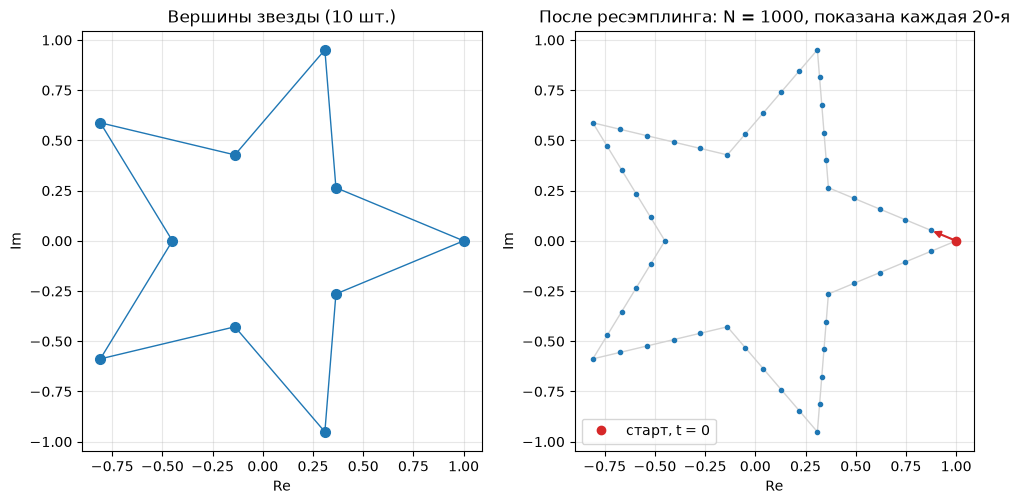

In [106]:
V = star(p)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

ax = axes[0]
V_closed = np.append(V, V[0])
ax.plot(V_closed.real, V_closed.imag, color="tab:blue", lw=1)
ax.plot(V.real, V.imag, "o", color="tab:blue", ms=7)
ax.set_title(f"Вершины звезды ({2 * p} шт.)")

ax = axes[1]
z_closed = np.append(z_star, z_star[0])
ax.plot(z_closed.real, z_closed.imag, color="lightgray", lw=1)
step = 20
ax.plot(z_star[::step].real, z_star[::step].imag, ".", color="tab:blue", ms=6)
ax.plot(z_star[0].real, z_star[0].imag, "o", color="tab:red", ms=6, label="старт, t = 0")
ax.annotate("", xy=(z_star[step].real, z_star[step].imag),
            xytext=(z_star[0].real, z_star[0].imag),
            arrowprops=dict(arrowstyle="-|>", color="tab:red", lw=1.5))
ax.set_title(f"После ресэмплинга: N = {N}, показана каждая {step}-я")
ax.legend(loc="lower left")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("Re"); ax.set_ylabel("Im")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figs/data_star.png", dpi=200)
plt.show()

Получили $N = 1000$ точек звезды, равномерно расставленных по длине: шаг между соседними точками постоянный, центр в нуле, обход против часовой стрелки с вершины луча. Это равномерная сетка $t_n = \frac{n}{N}$, на которой работают все свойства ДПФ.

И попробуем провести похожие действия на собственном рисунке.

In [107]:
def load_svg(filename, n_per_seg=50):
    """Точки вдоль первого пути в SVG как комплексный массив (ось y направлена вверх)."""
    paths, _ = svgtools.svg2paths(filename)
    path = paths[0]
    T = np.linspace(0, 1, n_per_seg, endpoint=False)
    pts = []
    for seg in path:
        pts.extend(seg.point(t) for t in T)
    return np.conj(np.array(pts))

V_m = load_svg("example/test_m.svg")
z_m = normalize(resample_arclength(V_m, 1000))

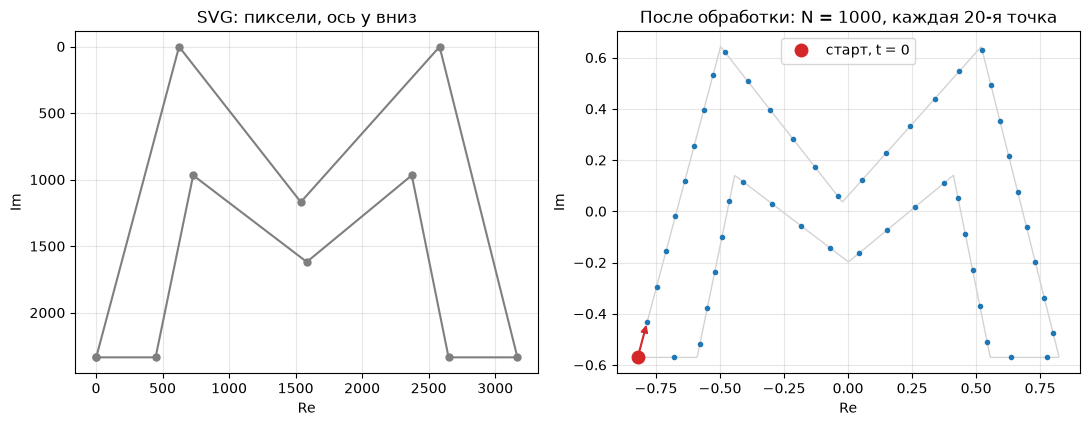

In [108]:
paths, _ = svgtools.svg2paths("example/test_m.svg")
raw = np.array([seg.start for seg in paths[0]])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

ax = axes[0]
raw_closed = np.append(raw, raw[0])
ax.plot(raw_closed.real, raw_closed.imag, "-o", color="tab:gray", ms=5)
ax.invert_yaxis()
ax.set_title("SVG: пиксели, ось y вниз")

ax = axes[1]
z_closed = np.append(z_m, z_m[0])
ax.plot(z_closed.real, z_closed.imag, color="lightgray", lw=1)
step = 20
ax.plot(z_m[::step].real, z_m[::step].imag, ".", color="tab:blue", ms=6)
ax.plot(z_m[0].real, z_m[0].imag, "o", color="tab:red", ms=9, label="старт, t = 0")
ax.annotate("", xy=(z_m[step].real, z_m[step].imag), xytext=(z_m[0].real, z_m[0].imag),
            arrowprops=dict(arrowstyle="-|>", color="tab:red", lw=1.5))
ax.set_title(f"После обработки: N = {len(z_m)}, каждая {step}-я точка")
ax.legend(loc="upper center")

for ax in axes:
    ax.set_aspect("equal")
    ax.set_xlabel("Re"); ax.set_ylabel("Im")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figs/data_m.png", dpi=200)
plt.show()

### 4. Приближение $M$ векторами

Имея коэффициенты $c_k$ будем приближать кривую суммой не всех, а только $M$ векторов. Логично взять $M$ **самых длинных**, то есть с наибольшими $|c_k|$: они вносят наибольший вклад (оптимальность этого выбора докажем в разделе 5).

Пусть $S$ - множество выбранных частот, $|S| = M$:
$$\hat{z}_M(t) = \sum_{k \in S}c_k e^{2 \pi i k t}$$

Выберем **меру оценки** - средний квадрат расстояния между точками кривой и приближения: 
$$MSE(M) = \frac{1}{N}\sum_{n = 0}^{N - 1}|z_n - \hat{z}_M(t_n)|^2$$

Чтобы сравнивать разные рисунки, удобна **относительная ошибка** $$\frac{MSE(M)}{\frac{1}{N} \sum_{n = 0}^{N - 1}|z_n|^2}$$

Тогда по дискретному равенству Парсеваля ошибка равна сумме квадратов выброшенных коэффициентов:
$$MSE(M) = \sum_{k \notin S}|c_k|^2$$

Проверим это численно.

In [109]:
def dft_coeffs(z):
    """Коэффициенты c_k и соответствующие частоты k."""
    N = len(z)
    c = np.fft.fft(z) / N
    k = np.fft.fftfreq(N, d=1/N).astype(int)
    return k, c

def top_m(k, c, M):
    """M частот и коэффициентов с наибольшими |c_k|, по убыванию |c_k|."""
    order = np.argsort(-np.abs(c))
    idx = order[:M]
    return k[idx], c[idx]

def evaluate(coeffs, freqs, t):
    """Значения суммы sum c_k e^{2πikt} в моментах t."""
    return np.exp(2j * np.pi * t[:, None] * freqs[None, :]) @ coeffs

def mse(z, z_hat):
    return np.mean(np.abs(z - z_hat) ** 2)

In [110]:
k_s, c_s = dft_coeffs(z_star)
t_grid = np.arange(N) / N
energy = np.mean(np.abs(z_star) ** 2)

for M in [1, 3, 10, 30, 100]:
    fr, co = top_m(k_s, c_s, M)
    err = mse(z_star, evaluate(co, fr, t_grid))
    parseval = np.sum(np.abs(c_s) ** 2) - np.sum(np.abs(co) ** 2)
    print(f"M = {M:3d}   MSE = {err:.3e}   Парсеваль = {parseval:.3e}   отн. ошибка = {err / energy:.2e}")

M =   1   MSE = 3.014e-02   Парсеваль = 3.014e-02   отн. ошибка = 5.77e-02
M =   3   MSE = 4.281e-04   Парсеваль = 4.281e-04   отн. ошибка = 8.20e-04
M =  10   MSE = 1.878e-05   Парсеваль = 1.878e-05   отн. ошибка = 3.60e-05
M =  30   MSE = 7.820e-07   Парсеваль = 7.820e-07   отн. ошибка = 1.50e-06
M = 100   MSE = 3.541e-08   Парсеваль = 3.541e-08   отн. ошибка = 6.78e-08


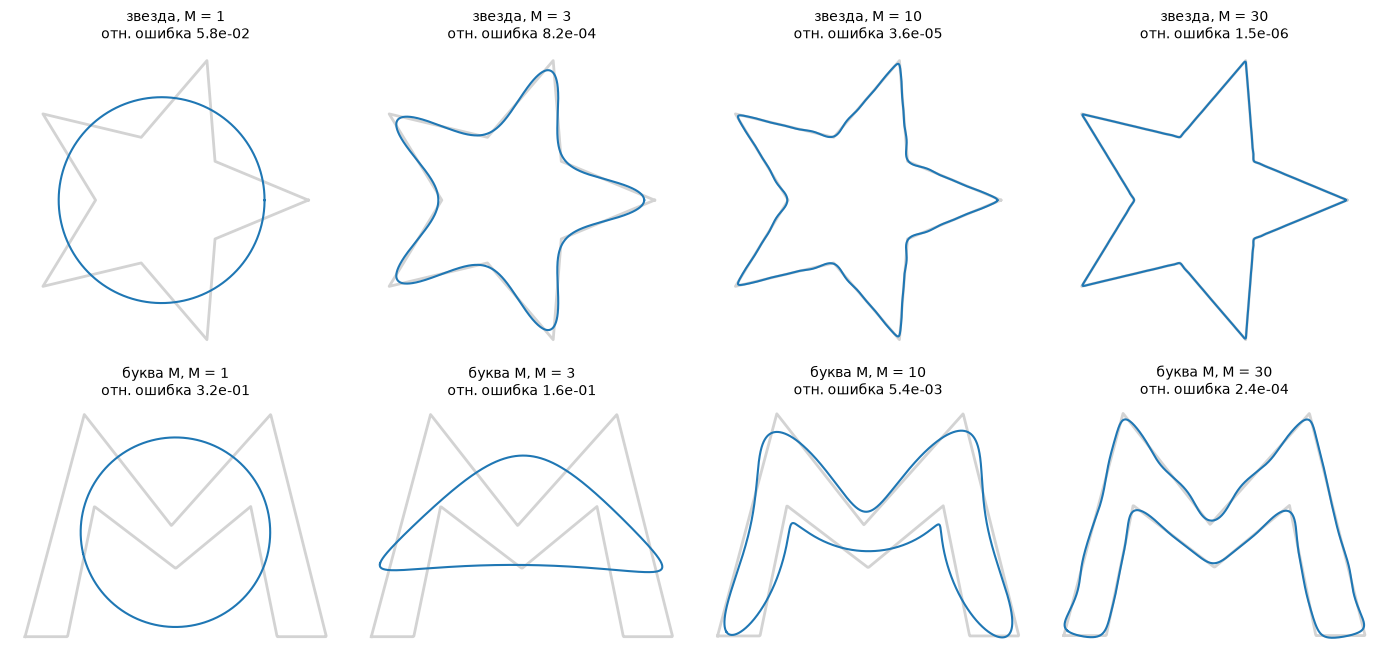

In [111]:
curves = {"звезда": z_star, "буква M": z_m}
Ms = [1, 3, 10, 30]
t_grid = np.arange(N) / N
t_fine = np.linspace(0, 1, 3000)

fig, axes = plt.subplots(len(curves), len(Ms), figsize=(14, 7))

for row, (name, z) in enumerate(curves.items()):
    k, c = dft_coeffs(z)
    energy = np.mean(np.abs(z) ** 2)
    z_closed = np.append(z, z[0])

    for col, M in enumerate(Ms):
        ax = axes[row, col]
        fr, co = top_m(k, c, M)
        rel = mse(z, evaluate(co, fr, t_grid)) / energy
        z_hat = evaluate(co, fr, t_fine)

        ax.plot(z_closed.real, z_closed.imag, color="lightgray", lw=2)
        ax.plot(z_hat.real, z_hat.imag, color="tab:blue", lw=1.5)
        ax.set_title(f"{name}, M = {M}\nотн. ошибка {rel:.1e}", fontsize=10)
        ax.set_aspect("equal")
        ax.axis("off")

plt.tight_layout()
plt.savefig("figs/approx.png", dpi=200)
plt.show()

1. Ошибка, посчитанная напрямую, действительно совпадает с суммой выброшенных $|c_k|^2$ - равенство Парсеваля подтверждено.
2. Звезде хватает уже около 10 векторов, букве М требуется около 30: чем "проще" и симметричнее кривая, тем легче ее аппроксимировать.
3. Острые углы восстанавливаются последними: они "стоят" больших частот.

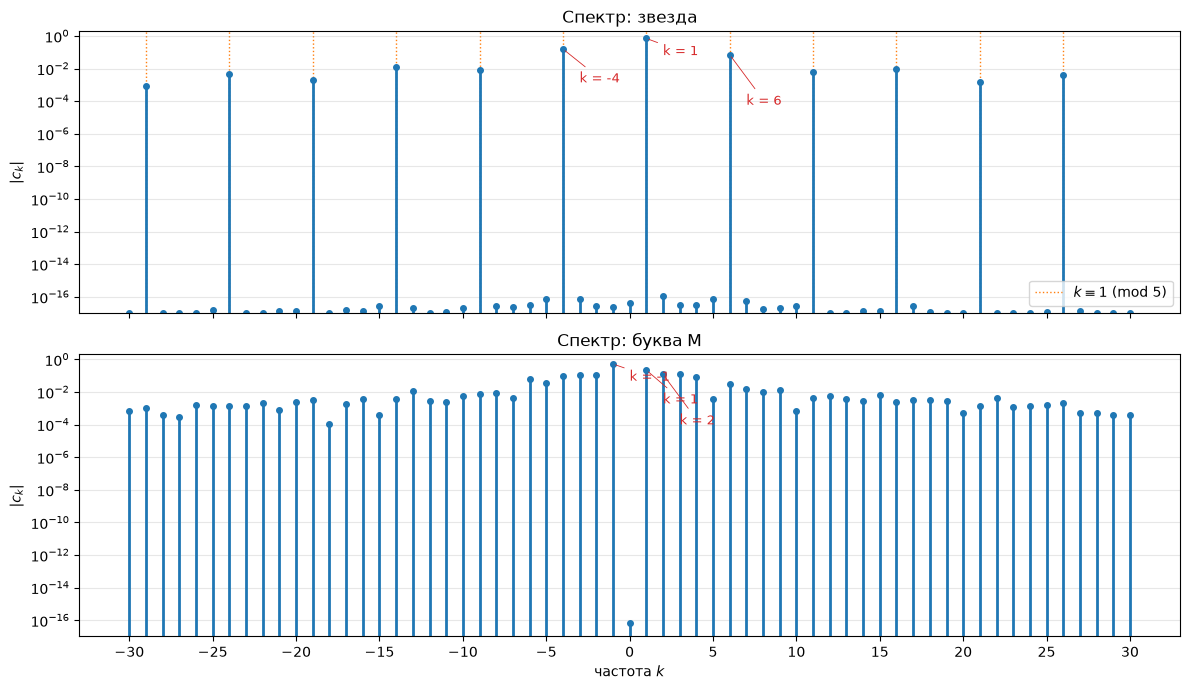

In [112]:
K = 30
k_s, c_s = dft_coeffs(z_star)
k_m, c_m = dft_coeffs(z_m)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
floor = 1e-17

for ax, (name, k, c) in zip(axes, [("звезда", k_s, c_s), ("буква M", k_m, c_m)]):
    sel = np.abs(k) <= K
    kk, aa = k[sel], np.maximum(np.abs(c[sel]), floor)
    ax.vlines(kk, floor, aa, color="tab:blue", lw=2)
    ax.plot(kk, aa, "o", color="tab:blue", ms=4)
    ax.set_yscale("log")
    ax.set_ylim(floor, 2)
    ax.set_ylabel("$|c_k|$")
    ax.set_title(f"Спектр: {name}")
    ax.grid(True, axis="y", alpha=0.3)

    top = np.argsort(-np.abs(c))[:3]
    for j, i in enumerate(top):
        ax.annotate(f"k = {k[i]}", (k[i], abs(c[i])), textcoords="offset points",
                    xytext=(12, -12 - 12 * j), fontsize=9, color="tab:red",
                    arrowprops=dict(arrowstyle="-", color="tab:red", lw=0.6))

for j, kk in enumerate(range(-K + 1, K + 1, p)):
    axes[0].axvline(kk, color="tab:orange", ls=":", lw=1, zorder=0,
                    label=f"$k \\equiv 1$ (mod {p})" if j == 0 else None)
axes[0].legend(loc="lower right")

axes[1].set_xlabel("частота $k$")
axes[1].set_xticks(range(-K, K + 1, 5))
plt.tight_layout()
plt.savefig("figs/spectrum.png", dpi=200)
plt.show()

1. У звезды вклад дают только $k \equiv 1 \pmod 5$, остальные - машинный ноль. Это следствие симметрии.
2. Энергия буквы М размазана по многим частотам.
3. Главный коэффициент для буквы М - $c_{-1}$, потому что обход идет по часовой стрелке.

In [113]:
mask = (k_s - 1) % p != 0
print("max |c_k| вне k = 1 (mod p):", np.abs(c_s[mask]).max())
print("10 самых больших частот:", top_m(k_s, c_s, 10)[0])

max |c_k| вне k = 1 (mod p): 1.1726935091898543e-16
10 самых больших частот: [  1  -4   6 -14  16  -9  11 -24  26 -34]


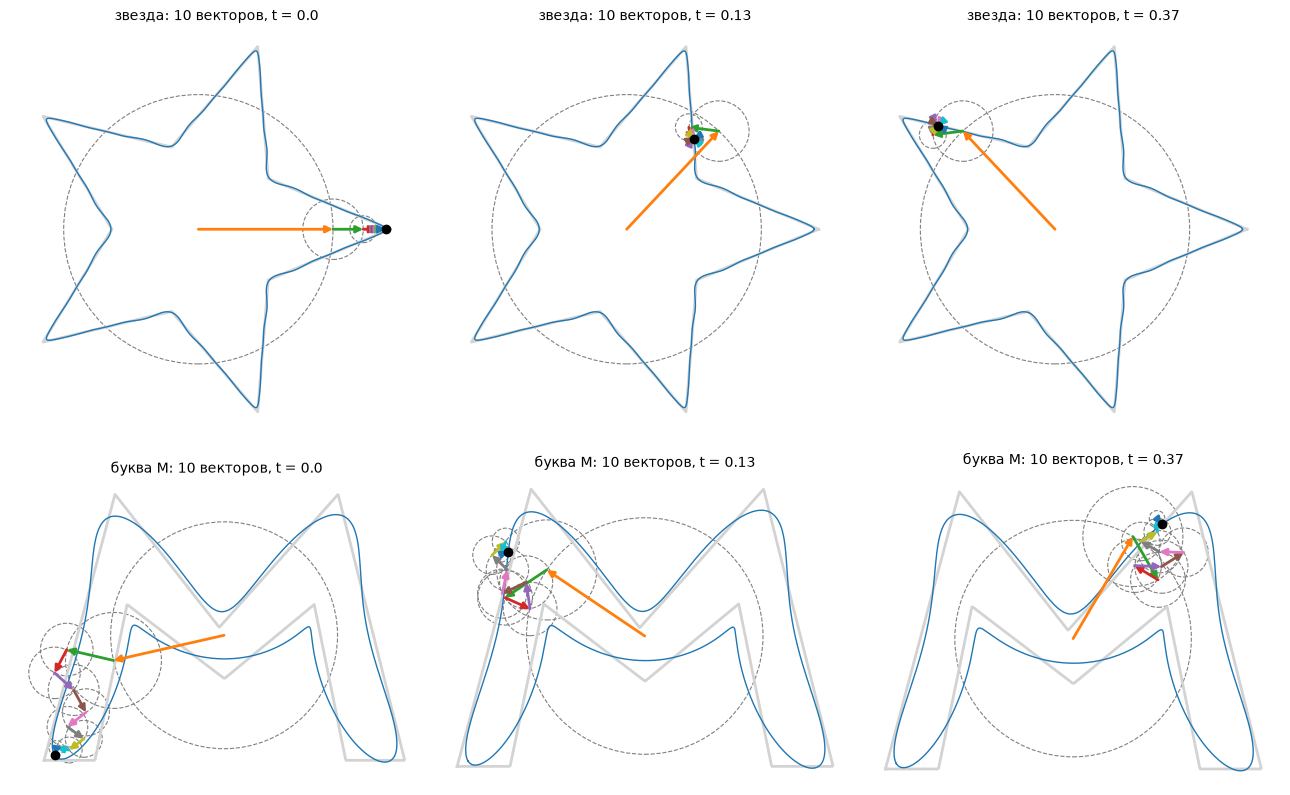

In [114]:
M_vec = 10
t_fine = np.linspace(0, 1, 3000)
times = [0.0, 0.13, 0.37]

fig, axes = plt.subplots(2, len(times), figsize=(13, 8.5))
for row, (name, z) in enumerate({"звезда": z_star, "буква M": z_m}.items()):
    k, c = dft_coeffs(z)
    fr, co = top_m(k, c, M_vec)
    z_hat = evaluate(co, fr, t_fine)
    z_closed = np.append(z, z[0])
    for col, t0 in enumerate(times):
        ax = axes[row, col]
        ax.plot(z_closed.real, z_closed.imag, color="lightgray", lw=2)
        ax.plot(z_hat.real, z_hat.imag, color="tab:blue", lw=1)
        draw_vectors(ax, co, fr, t0)
        ax.set_title(f"{name}: {M_vec} векторов, t = {t0}", fontsize=10)
        ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.savefig("figs/epicycles.png", dpi=200)
plt.show()

Приближение $M$ векторами с наибольшими $|c_k|$ восстанавливает рисунок: звезде хватает около 10 векторов, букве M — около 30. Ошибка точно равна сумме выброшенных $|c_k|^2$ (Парсеваль). Спектр звезды подтверждает теорию симметрии. Остаётся вопрос: оптимален ли выбор самых больших коэффициентов и как он связан с тремя подходами из условия?

### 5. Почему три подхода совпадают

#### 5.1. Подбор коэффициентов как МНК

Пусть набор частот $S = \{k_1, \dots, k_M\}$ уже выбран. Нужно подобрать коэффициенты $x_1, \dots, x_M$ так, чтобы модель


$$\hat z_n = \sum_{j=1}^{M} x_j\, e^{2\pi i k_j t_n}$$

была как можно ближе к точкам рисунка $z_n$.

Запишем в матричном виде. Матрица $A \in \mathbb C^{N\times M}$ с элементами $A_{nj} = e^{2\pi i k_j t_n}$: $j$-й столбец $a_j$ — это $j$-я гармоника, вычисленная во всех $N$ точках. Тогда $\hat z = Ax$, и задача:


$$\min_{x \in \mathbb C^M}\ \frac1N\|z - Ax\|^2 .$$

Это **метод наименьших квадратов**. Функция квадратичная и выпуклая, поэтому минимум единственный (если столбцы $A$ линейно независимы) и находится формулой, без итераций.

**Геометрия.** Все векторы вида $Ax$ образуют подпространство, натянутое на столбцы $A$. Ближайшая к $z$ точка подпространства — ортогональная проекция: остаток $r = z - Ax^\star$ перпендикулярен каждому столбцу, $\langle r, a_j\rangle = 0$. В матричной форме $A^H r = 0$, где $A^H = \overline{A}^{\,T}$ (транспонирование и сопряжение). Подставив $r = z - Ax$:


$$A^H A\, x = A^H z .$$

Матрица $G = A^HA$ — матрица Грама: $G_{jm} = \langle a_m, a_j\rangle$, попарные скалярные произведения столбцов.

#### 5.2. Ортогональность: МНК = ДПФ

На равномерной сетке $t_n = n/N$ для целых $k \ne m$ (в диапазоне длины не больше $N$):


$$\langle a_k, a_m\rangle = \sum_{n=0}^{N-1} e^{2\pi i (k-m) n/N} = 0, \qquad \|a_k\|^2 = N .$$

Это сумма геометрической прогрессии со знаменателем $q = e^{2\pi i (k-m)/N} \ne 1$ и $q^N = 1$, поэтому $\sum q^n = \frac{1 - q^N}{1-q} = 0$. Геометрически: числа $q^n$ — вершины правильного многоугольника на единичной окружности, их сумма равна нулю.

Значит, $A^HA = N\cdot I$, и решение нормальных уравнений:


$$x = \frac1N A^H z, \qquad x_j = \frac1N\sum_{n} z_n e^{-2\pi i k_j n/N} = c_{k_j}.$$

Это в **точности коэффициенты ДПФ**. И главное: $j$-й коэффициент зависит только от $j$-го столбца. Какие ещё частоты взяты в модель, на него не влияет.

In [115]:
def design_matrix(t, freqs):
    """A[n, j] = exp(2πi * freqs[j] * t[n])."""
    return np.exp(2j * np.pi * freqs[None, :] * t[:, None])

t_grid = np.arange(N) / N
freqs = np.arange(-10, 11)
A = design_matrix(t_grid, freqs)

G = A.conj().T @ A
offdiag = G - np.diag(np.diag(G))
print("диагональ:", np.unique(np.round(np.diag(G).real, 8)))
print("max |вне диагонали|:", np.abs(offdiag).max())

for name, z in [("звезда", z_star), ("буква M", z_m)]:
    x, *_ = np.linalg.lstsq(A, z, rcond=None)
    k, c = dft_coeffs(z)
    c_same = np.array([c[k == f][0] for f in freqs])
    print(name, "max |МНК − ДПФ|:", np.abs(x - c_same).max())

диагональ: [1000.]
max |вне диагонали|: 2.5581491544193444e-12
звезда max |МНК − ДПФ|: 5.835086458827516e-16
буква M max |МНК − ДПФ|: 3.1835838817813215e-16


In [116]:
sub = np.array([1, -1, 2])
A_sub = design_matrix(t_grid, sub)
x_sub, *_ = np.linalg.lstsq(A_sub, z_m, rcond=None)
k, c = dft_coeffs(z_m)
print("МНК по 3 частотам:", np.round(x_sub, 6))
print("ДПФ на тех же     :", np.round([c[k == f][0] for f in sub], 6))

МНК по 3 частотам: [-0.213201+0.049595j -0.504685-0.114765j -0.055794-0.106165j]
ДПФ на тех же     : [-0.213201+0.049595j -0.504685-0.114765j -0.055794-0.106165j]


На равномерной сетке гармоники ортогональны: МНК по любому набору частот даёт коэффициенты ДПФ, и каждый коэффициент не зависит от того, какие ещё частоты в модели.

#### 5.3. Три подхода как алгоритмы

Пусть есть **словарь** допустимых частот $D$ (например, все целые от $-64$ до $64$) и столбцы $a_k$ для $k \in D$. Нормируем их: $\tilde a_k = a_k / \|a_k\|$ (на равномерной сетке $\|a_k\| = \sqrt N$). Нужно выбрать $M$ частот и коэффициенты.

**Подход 1 — последовательно (Matching Pursuit, MP)**. Остаток $r \leftarrow z$. Повторить $M$ раз:

1. посчитать проекции остатка на все столбцы $p_k = \langle r, \tilde a_k\rangle$;
2. выбрать $k^* = \arg\max_k |p_k|$ — частоту, которая лучше всего объясняет текущий остаток;
3. $r \leftarrow r - p_{k^*}\tilde a_{k^*}$. Старые коэффициенты не меняются.

**Подход 2 — последовательно с дообучением (Orthogonal Matching Pursuit, OMP)**. Шаги 1–2 те же, но после выбора $k^*$ добавляем её в набор $S$ и заново решаем МНК по всем частотам из $S$: $x_S = \arg\min\|z - A_Sx\|^2$, $r \leftarrow z - A_Sx_S$.

**Подход 3 — все сразу.** Задаём $M$ и решаем


$$\min_{|S| = M}\ \min_x \|z - A_Sx\|^2 .$$

Если набор $S$ известен — это один МНК. Если его надо выбрать, это перебор $\binom{|D|}{M}$ наборов: при $|D| = 129$ и $M = 10$ это около $2.5\cdot 10^{14}$. В общем случае задача NP-трудна. Поэтому используем естественную эвристику: $M$ частот с наибольшими $|\langle z, \tilde a_k\rangle|$, затем МНК.

#### 5.4. Главная теорема

**Теорема.** Пусть сетка равномерная ($t_n = n/N$), а словарь — целые частоты из диапазона длины не больше $N$. Тогда при каждом $M$ подходы 1, 2 и 3 дают одинаковое приближение, и его ошибка минимальна среди всех наборов из $M$ частот.

Из раздела 5.2: $\langle a_k, a_m\rangle = N$ при $k = m$ и $0$ при $k \ne m$ (для $k, m$ из диапазона длины $\le N$).

---

**(а) МНК по любому набору даёт коэффициенты ДПФ.**
Пусть $S \subseteq D$ — любой набор частот, $A_S$ — матрица из столбцов $a_k$, $k \in S$. По ортогональности $A_S^H A_S = N I$, и нормальные уравнения $A_S^H A_S x = A_S^H z$ дают
$$x = \frac1N A_S^H z, \qquad x_k = \frac1N \langle z, a_k\rangle = c_k \quad (k \in S).$$
Коэффициент при частоте $k$ равен $c_k$ **независимо от того, какие ещё частоты входят в $S$**.

---

**(б) Подход 1 (MP) и подход 2 (OMP) совпадают.**
Докажем индукцией по числу шагов $m$: после $m$ шагов оба алгоритма выбрали один и тот же набор $S_m$ и построили одно и то же приближение
$$\hat z^{(m)} = \sum_{k \in S_m} c_k a_k .$$
*База* ($m = 0$): $S_0 = \varnothing$, $\hat z^{(0)} = 0$ у обоих.

*Переход.* Остаток $r = z - \hat z^{(m)}$. Посчитаем его проекции на столбцы словаря:
$$\langle r, a_k\rangle = \langle z, a_k\rangle - \sum_{j \in S_m} c_j \langle a_j, a_k\rangle =
\begin{cases} N c_k - N c_k = 0, & k \in S_m, \\ N c_k, & k \notin S_m. \end{cases}$$
Значит, $\langle r, \tilde a_k\rangle = \sqrt N\, c_k$ для невыбранных частот и $0$ для выбранных.

- *Выбор частоты.* Оба алгоритма берут $k^* = \arg\max_k |\langle r, \tilde a_k\rangle|$, то есть невыбранную частоту с наибольшим $|c_k|$. Уже выбранную частоту MP повторно не возьмёт: её проекция равна нулю. (Если все оставшиеся проекции тоже нулевые, остаток уже ноль, и дальше ничего не меняется.)
- *MP.* Обновление $r \leftarrow r - \langle r, \tilde a_{k^*}\rangle\, \tilde a_{k^*} = r - \sqrt N c_{k^*} \cdot \frac{a_{k^*}}{\sqrt N} = r - c_{k^*} a_{k^*}$, то есть к приближению добавляется $c_{k^*} a_{k^*}$, а старые слагаемые не меняются.
- *OMP.* Решает МНК по набору $S_{m+1} = S_m \cup \{k^*\}$ и по (а) получает коэффициенты $c_k$, $k \in S_{m+1}$.

В обоих случаях $\hat z^{(m+1)} = \sum_{k \in S_{m+1}} c_k a_k$. Дообучение не меняет старых коэффициентов: они уже оптимальны.

---

**(в) Ошибка равна сумме выброшенных $|c_k|^2$.**
Пусть $F$ — полный набор из $N$ подряд идущих частот, содержащий словарь $D$. Столбцы $\{a_k\}_{k \in F}$ — ортогональный базис $\mathbb C^N$, и $z = \sum_{k \in F} c_k a_k$ (обратное ДПФ). Тогда для приближения $\hat z_S = \sum_{k \in S} c_k a_k$
$$z - \hat z_S = \sum_{k \in F \setminus S} c_k a_k, \qquad
\frac1N \|z - \hat z_S\|^2 = \frac1N \sum_{k, m \notin S} c_k \overline{c_m} \langle a_k, a_m\rangle = \sum_{k \in F \setminus S} |c_k|^2 .$$
Это дискретное равенство Парсеваля (проверено численно в разделе 4).

---

**(г) Это оптимум, и подход 3 даёт то же самое.**
Из (в):
$$\mathrm{MSE}(S) = \underbrace{\sum_{k \in F} |c_k|^2}_{\text{не зависит от } S} - \sum_{k \in S} |c_k|^2 .$$
Ошибка минимальна, когда $\sum_{k \in S}|c_k|^2$ максимальна, то есть когда $S$ — это $M$ частот словаря с наибольшими $|c_k|$.

- *Подход 3* ищет $\min_{|S| = M} \min_x \|z - A_S x\|^2$. По (а) внутренний минимум для любого $S$ достигается при $x_k = c_k$ и равен $\mathrm{MSE}(S)$, поэтому лучший набор — $M$ наибольших $|c_k|$. Эвристика «наибольшие $|\langle z, \tilde a_k\rangle|$» выбирает тот же набор, так как $\langle z, \tilde a_k\rangle = \sqrt N c_k$.
- *Подходы 1 и 2* по (б) на каждом шаге добавляют невыбранную частоту с наибольшим $|c_k|$, поэтому после $M$ шагов их набор — те же $M$ наибольших $|c_k|$.

Все три подхода дают одно и то же приближение с минимально возможной ошибкой. $\blacksquare$

На равномерной сетке три способа из условия — это один и тот же алгоритм: «взять $M$ самых больших коэффициентов ДПФ». Дообучение ничего не даёт, а «обучение всего сразу» сводится к тому же выбору. Именно это мы делали в разделе 4, и по теореме это был оптимальный выбор.

#### 5.5. Когда теорема перестаёт работать

Всё держалось на пункте (а): $A^HA = NI$. Ортогональность ломается, если:

1. точки взяты неравномерно по $t$. Например, сырые точки с мышки: где рука вела медленно, точек больше. Или специально сгущённая сетка;
2. частоты нецелые или обучаемые (раздел 7);
3. словарь переполнен: частот больше, чем точек.

Тогда коэффициенты «мешают» друг другу: добавление новой частоты меняет оптимальные значения старых, а проекция на столбец уже не равна коэффициенту. Ожидаем, что подходы разойдутся: дообучение (OMP) будет лучше MP, а выбор «топ-$M$ по проекции» может проиграть обоим.

равномерная max вне диагонали: 2.5581491544193445e-15
неравномерная max вне диагонали: 0.2091721140968758


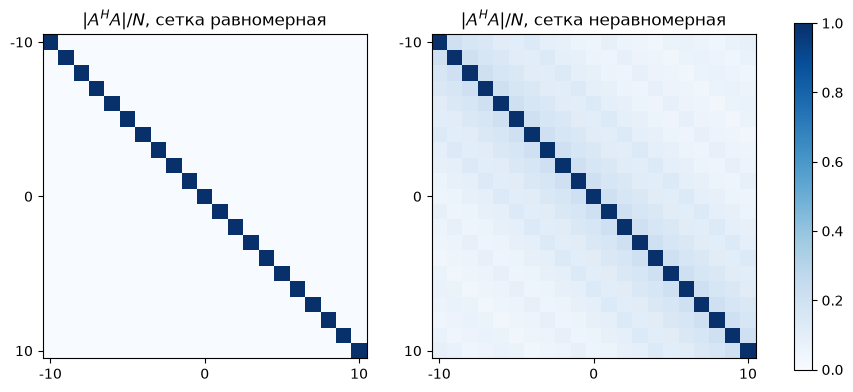

In [117]:
rng = np.random.default_rng(0)
t_nonuni = np.sort(rng.random(N) ** 1.8)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (name, t) in zip(axes, [("равномерная", t_grid), ("неравномерная", t_nonuni)]):
    A_t = design_matrix(t, freqs)
    G_t = np.abs(A_t.conj().T @ A_t) / N
    im = ax.imshow(G_t, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"$|A^HA|/N$, сетка {name}")
    ax.set_xticks([0, 10, 20]); ax.set_xticklabels([-10, 0, 10])
    ax.set_yticks([0, 10, 20]); ax.set_yticklabels([-10, 0, 10])
    print(name, "max вне диагонали:", np.abs(G_t - np.diag(np.diag(G_t))).max())
fig.colorbar(im, ax=axes, fraction=0.03)
plt.savefig("figs/gram.png", dpi=200, bbox_inches="tight")
plt.show()

Мы доказали, что на равномерной сетке три подхода совпадают и оптимальны, а численно — что МНК = ДПФ и коэффициенты независимы. На неравномерной сетке матрица Грама перестаёт быть диагональной, и теорема не работает. Проверим в эксперименте, как именно расходятся подходы.

### 6. Эксперимент A: фиксированные целые частоты

**Зачем этот раздел.** В разделе 5 мы доказали, что на равномерной сетке три подхода совпадают, и предсказали, что на неравномерной они разойдутся. Здесь проверяем оба утверждения численно: реализуем три алгоритма из 5.3 и сравниваем их ошибки при $M = 1, \dots, 40$.

#### 6.1. Постановка эксперимента

**Что проверяем.** (1) На равномерной сетке ошибки трёх подходов совпадают при каждом $M$ (теорема 5.4). (2) На неравномерной сетке подходы расходятся: OMP лучше MP, а «топ-$M$ + МНК» может проиграть обоим (гипотеза 5.5).

**Условия.**

- Кривые: звезда и буква M, $N = 1000$ точек.
- Словарь: целые частоты $D = \{-64, \dots, 64\}$, всего 129.
- $M = 1, \dots, 40$.
- Две сетки: равномерная $t_n = n/N$ и неравномерная `t_nonuni` (сгущение к началу).
- Мера качества — $MSE$ в точках сетки.

In [118]:
def matching_pursuit(A, z, M):
    """Подход 1 (MP). Возвращает массив ошибок после каждого шага и список выбранных столбцов."""
    An = A / np.linalg.norm(A, axis=0)
    r = z.copy()
    errs, chosen = [], []
    for m in range(M):
        p = An.conj().T @ r
        j = int(np.argmax(np.abs(p)))
        r = r - p[j] * An[:, j]
        chosen.append(j)
        errs.append(np.mean(np.abs(r) ** 2))
    return np.array(errs), chosen


def omp(A, z, M):
    """Подход 2 (OMP): после каждого выбора — МНК по всем выбранным столбцам."""
    An = A / np.linalg.norm(A, axis=0)
    r = z.copy()
    S, errs = [], []
    for m in range(M):
        p = An.conj().T @ r
        p[S] = 0
        j = int(np.argmax(np.abs(p)))
        S.append(j)
        x, *_ = np.linalg.lstsq(A[:, S], z, rcond=None)
        r = z - A[:, S] @ x
        errs.append(np.mean(np.abs(r) ** 2))
    return np.array(errs), S


def all_at_once(A, z, M):
    """Подход 3: выбрать M столбцов сразу по |проекции z| и решить МНК. Возвращает одну ошибку."""
    An = A / np.linalg.norm(A, axis=0)
    p = np.abs(An.conj().T @ z)
    S = np.argsort(-p)[:M]
    x, *_ = np.linalg.lstsq(A[:, S], z, rcond=None)
    return np.mean(np.abs(z - A[:, S] @ x) ** 2)

In [119]:
D = np.arange(-64, 65)
A_uni = design_matrix(t_grid, D)
e1, _ = matching_pursuit(A_uni, z_m, 10)
e2, _ = omp(A_uni, z_m, 10)
e3 = all_at_once(A_uni, z_m, 10)
print(e1[-1], e2[-1], e3)

0.0020968510452241706 0.00209685104522417 0.00209685104522417


Чтобы сравнивать на неравномерной сетке, нужны точки той же кривой, но взятые в моменты t_nonuni. Кривая у нас задана $N$ точками на равномерной сетке, поэтому значение в произвольный момент $t$ получаем линейной интерполяцией между соседними точками, с учётом периодичности ($t = 1$ совпадает с $t = 0$).

In [120]:
def sample_at(z, t):
    """Значения кривой z (заданной на равномерной сетке) в произвольных моментах t ∈ [0, 1)."""
    t_grid = np.arange(len(z)) / len(z)
    x = np.interp(t, t_grid, z.real, period=1)
    y = np.interp(t, t_grid, z.imag, period=1)
    return x + 1j * y

z_star_non = sample_at(z_star, t_nonuni)
z_m_non = sample_at(z_m, t_nonuni)

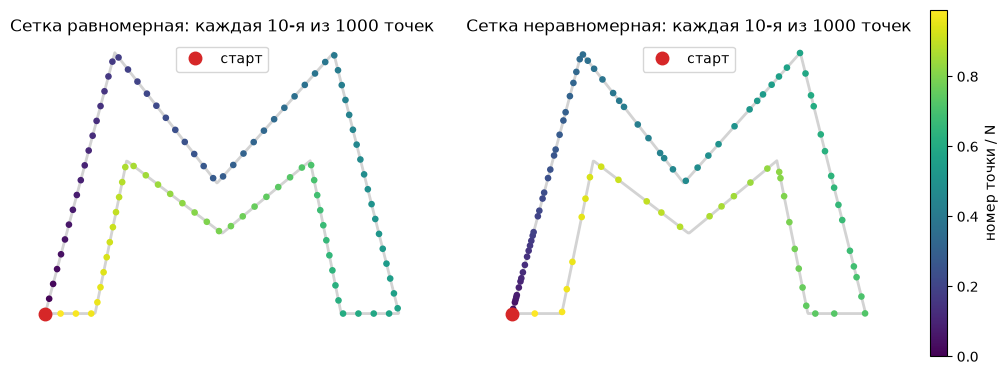

In [121]:
step = 10
z_closed = np.append(z_m, z_m[0])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, pts) in zip(axes, [("равномерная", z_m), ("неравномерная", z_m_non)]):
    ax.plot(z_closed.real, z_closed.imag, color="lightgray", lw=2)
    sc = ax.scatter(pts[::step].real, pts[::step].imag,
                    c=np.arange(0, len(pts), step) / len(pts),
                    cmap="viridis", s=14, zorder=3)
    ax.plot(pts[0].real, pts[0].imag, "o", color="tab:red", ms=9, zorder=4, label="старт")
    ax.set_title(f"Сетка {name}: каждая {step}-я из {len(pts)} точек")
    ax.set_aspect("equal")
    ax.axis("off")
    ax.legend(loc="upper center")

fig.colorbar(sc, ax=axes, fraction=0.03, label="номер точки / N")
plt.savefig("figs/grids.png", dpi=200, bbox_inches="tight")
plt.show()

Одна и та же кривая, 1000 точек. Справа точки взяты в моменты $t_n = u_n^{1.8}$, где $u_n$ — равномерные случайные числа: степень сжимает их к нулю, поэтому точки сгущаются у начала обхода. На такой сетке гармоники неортогональны (матрица Грама в разделе 5.5).

In [122]:
M_max = 40
results = {}

cases = {
    ("звезда", "равномерная"):   (t_grid,   z_star),
    ("звезда", "неравномерная"): (t_nonuni, z_star_non),
    ("буква M", "равномерная"):  (t_grid,   z_m),
    ("буква M", "неравномерная"): (t_nonuni, z_m_non),
}
for key, (t, z) in cases.items():
    A_t = design_matrix(t, D)
    e1, chosen = matching_pursuit(A_t, z, M_max)
    e2, _ = omp(A_t, z, M_max)
    e3 = np.array([all_at_once(A_t, z, M) for M in range(1, M_max + 1)])
    results[key] = (e1, e2, e3)
    print(key, "повторов в MP:", M_max - len(set(chosen)))

('звезда', 'равномерная') повторов в MP: 3
('звезда', 'неравномерная') повторов в MP: 14
('буква M', 'равномерная') повторов в MP: 0
('буква M', 'неравномерная') повторов в MP: 15


In [123]:
Ms_show = [1, 3, 5, 10, 20, 40]
rows = []
for (curve, grid), (e1, e2, e3) in results.items():
    for M in Ms_show:
        rows.append({"кривая": curve, "сетка": grid, "M": M,
                     "MP": e1[M - 1], "OMP": e2[M - 1], "топ-M": e3[M - 1]})

table = pd.DataFrame(rows).set_index(["кривая", "сетка", "M"])
table.style.format("{:.2e}")

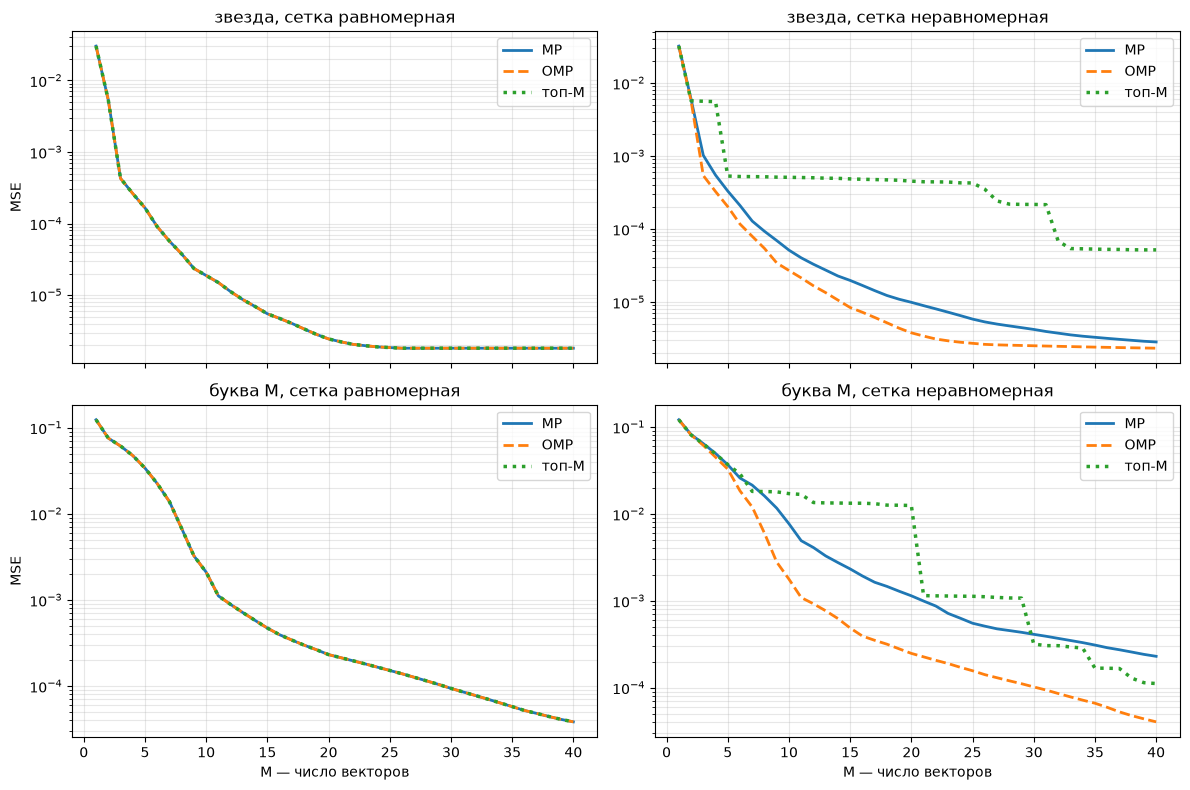

In [124]:
Ms = np.arange(1, M_max + 1)
styles = {"MP":    dict(color="tab:blue",   ls="-",  lw=2),
          "OMP":   dict(color="tab:orange", ls="--", lw=2),
          "топ-M": dict(color="tab:green",  ls=":",  lw=2.5)}
curves_order = ["звезда", "буква M"]
grids_order = ["равномерная", "неравномерная"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for i, curve in enumerate(curves_order):
    for j, grid in enumerate(grids_order):
        ax = axes[i, j]
        for (label, st), e in zip(styles.items(), results[(curve, grid)]):
            ax.semilogy(Ms, e, label=label, **st)
        ax.set_title(f"{curve}, сетка {grid}")
        ax.grid(True, which="both", alpha=0.3)
        ax.legend()
        if i == 1: ax.set_xlabel("M — число векторов")
        if j == 0: ax.set_ylabel("MSE")

plt.tight_layout()
plt.savefig("figs/expA.png", dpi=200)
plt.show()

#### 6.5. Выводы эксперимента A

1. **Равномерная сетка.** Ошибки MP, OMP и «топ-$M$ + МНК» совпадают при всех $M$ до машинной точности — эксперимент подтверждает теорему 5.4. У звезды ошибка выходит на полку $\approx 1.8\cdot 10^{-6}$ примерно после $M = 26$: в словаре $-64..64$ всего 26 частот вида $k \equiv 1 \pmod 5$, и все они уже выбраны. Остаток — вклад частот вне словаря, та самая неустранимая часть из пункта (в) доказательства.
2. **Неравномерная сетка: дообучение помогает.** OMP лучше MP при каждом $M > 1$: у буквы M при $M = 20$ ошибка $2.5\cdot 10^{-4}$ против $1.1\cdot 10^{-3}$. Без дообучения MP вынужден исправлять старые коэффициенты новыми шагами и выбирает частоты повторно — 14–15 повторов из 40.
3. **Неравномерная сетка: выбор набора сразу проигрывает.** «Топ-$M$ + МНК» идёт ступеньками и местами хуже обоих жадных подходов на порядок (у M при $M = 20$: $1.3\cdot 10^{-2}$). На неравномерной сетке у нужной частоты появляются соседи с большой проекцией (полосы у диагонали матрицы Грама), и выбор по проекциям исходной $z$ набирает таких «дублёров», которые почти ничего не добавляют. Жадные методы смотрят на остаток, где соседи уже выбранной частоты почти не видны.
4. **Честный подход 3** (перебор всех наборов из $M$ частот) неосуществим — около $2.5\cdot 10^{14}$ вариантов уже при $M = 10$, поэтому на практике это эвристика, и она проигрывает.

**Итог:** когда базис ортогонален, способ подбора не важен; когда ортогональность нарушена, важно учитывать, что новая частота добавляет к уже выбранным, — это и делает дообучение.

Дальше посмотрим, что меняется, если частоты не выбирать из словаря целых чисел, а обучать как непрерывные параметры.

### 7. Обучаемые частоты: теория

**Зачем:** в эксперименте A частоты были целыми и выбирались из словаря, и всё сводилось к МНК. Но в условии сказано «подбирать параметры», а частота — тоже параметр. Если сделать её непрерывной, задача становится настоящей оптимизацией, и здесь три подхода расходятся сильнее всего.

#### 7.1. Модель и функция потерь

Разрешим частотам быть **любыми вещественными** числами, а не только целыми:

$$\hat z(t) = \sum_{j=1}^{M} a_j\, e^{2\pi i\, \omega_j t}, \qquad a_j \in \mathbb C,\quad \omega_j \in \mathbb R .$$

Каждая компонента — по-прежнему вектор длины $|a_j|$, который вращается, но теперь он может делать нецелое число оборотов за период.

**Параметры.** У каждой компоненты три вещественных числа: частота $\omega_j$, $\mathrm{Re}\,a_j$ и $\mathrm{Im}\,a_j$. Оптимизаторы работают с вещественными векторами, поэтому комплексный коэффициент раскладываем на две части. Всего параметров $3M$; соберём их в один вектор
$$\theta = (\omega_1, \dots, \omega_M,\ \mathrm{Re}\,a_1, \dots, \mathrm{Re}\,a_M,\ \mathrm{Im}\,a_1, \dots, \mathrm{Im}\,a_M) \in \mathbb R^{3M}.$$

**Функция потерь** — та же MSE, что и раньше:
$$\mathcal L(\theta) = \frac1N\sum_{n=0}^{N-1}\big|\hat z(t_n) - z_n\big|^2 .$$

**Чем это отличается от раздела 6.**
- При **фиксированных** $\omega$ модель линейна по $a$, и задача по $a$ — снова МНК: выпуклая, решается формулой.
- По $\omega$ модель **нелинейна**: частота стоит внутри экспоненты. Формулы для оптимума нет, нужны итерационные методы — градиентный спуск или его улучшения. Для них нужен градиент (7.2).
- Целые частоты — частный случай. Если оптимум по $\omega$ лежит около целых чисел, модель должна сама их найти: это проверка корректности в разделе 8.

#### 7.2. Градиенты

**Градиент** $\nabla\mathcal L(\theta)$ — вектор частных производных по всем $3M$ параметрам. Он показывает направление наискорейшего роста потерь; шаг в обратную сторону уменьшает потери. Метод **L-BFGS** (будем использовать `scipy.optimize.minimize(..., jac=True, method="L-BFGS-B")`) принимает функцию, возвращающую пару (потери, градиент), сам оценивает кривизну по истории градиентов и сам подбирает длину шага. Он быстрее обычного градиентного спуска, но тоже **локальный**: спускается в ту яму, в которой стартовал.

**Лемма.** Если $r(\theta)$ — комплекснозначная функция вещественного параметра $\theta$, то
$$\frac{d}{d\theta}|r|^2 = 2\,\mathrm{Re}\Big(\overline{r}\,\frac{dr}{d\theta}\Big).$$
*Доказательство.* $|r|^2 = r\overline r$, по правилу произведения $(r\overline r)' = r'\,\overline r + r\,\overline{r'}$; второе слагаемое сопряжено первому, а $w + \overline w = 2\,\mathrm{Re}\,w$. $\square$

**Обозначения.** $E_{nj} = e^{2\pi i \omega_j t_n}$ — значение $j$-й гармоники в $n$-й точке, $r_n = \sum_j a_j E_{nj} - z_n$ — остаток в $n$-й точке. Тогда $\mathcal L = \frac1N\sum_n |r_n|^2$, и по лемме для любого вещественного параметра $\theta$
$$\frac{\partial\mathcal L}{\partial\theta} = \frac2N\sum_n \mathrm{Re}\Big(\overline{r_n}\,\frac{\partial r_n}{\partial\theta}\Big).$$

От параметров $j$-й компоненты в $r_n$ зависит только слагаемое $a_j E_{nj}$:
- по $\mathrm{Re}\,a_j$: при $a_j = u + iv$ производная $a_jE_{nj}$ по $u$ равна $E_{nj}$;
- по $\mathrm{Im}\,a_j$: производная по $v$ равна $iE_{nj}$;
- по $\omega_j$: $\frac{\partial}{\partial\omega_j}e^{2\pi i\omega_j t_n} = 2\pi i\, t_n\, e^{2\pi i\omega_j t_n}$, поэтому производная равна $a_j\cdot 2\pi i\, t_n E_{nj}$.

**Итог:**
$$\frac{\partial \mathcal L}{\partial\, \mathrm{Re}\,a_j} = \frac{2}{N}\,\mathrm{Re}\sum_n \overline{r_n}\, E_{nj}, \qquad
\frac{\partial \mathcal L}{\partial\, \mathrm{Im}\,a_j} = \frac{2}{N}\,\mathrm{Re}\sum_n \overline{r_n}\, iE_{nj}, \qquad
\frac{\partial \mathcal L}{\partial \omega_j} = \frac{2}{N}\,\mathrm{Re}\sum_n \overline{r_n}\,\big(2\pi i\, t_n\big)\, a_j E_{nj}.$$

**В матричном виде** (удобно для numpy): $E$ — матрица $N\times M$, $r$ — вектор остатков, $g = E^H r$. Тогда $\partial\mathcal L/\partial\,\mathrm{Re}\,a = \frac2N\mathrm{Re}\,g$ и $\partial\mathcal L/\partial\,\mathrm{Im}\,a = \frac2N\mathrm{Im}\,g$ (так как $\sum_n\overline{r_n}E_{nj} = \overline{g_j}$ и $\mathrm{Re}(i\overline{w}) = \mathrm{Im}\,w$).

**Проверка.** Ошибка в знаке или множителе — самая частая причина, почему оптимизатор «не работает». Поэтому в разделе 8 сначала сравним аналитический градиент с численным: $\frac{\mathcal L(\theta + h e_i) - \mathcal L(\theta - h e_i)}{2h}$ при $h = 10^{-6}$.

#### 7.3. Ландшафт: почему по частоте задача невыпуклая

**Выпуклость.** Функция выпукла, если хорда между любыми двумя точками графика лежит не ниже графика. Главное свойство: у выпуклой функции любой локальный минимум — глобальный, поэтому градиентный метод из любой стартовой точки приходит к лучшему ответу. МНК выпуклый. Покажем, что по частоте — нет.

**Шаг 1: исключаем коэффициент.** Возьмём одну компоненту ($M = 1$) и для каждой частоты $\omega$ подберём лучший $a$. На равномерной сетке $|E_n| = 1$, поэтому лучший коэффициент — проекция
$$a(\omega) = \hat c(\omega) = \frac1N\sum_n z_n e^{-2\pi i\omega t_n}$$
(«коэффициент Фурье на нецелой частоте»). Раскрывая квадрат модуля,
$$\frac1N\sum_n|aE_n - z_n|^2 = |a|^2 - 2\,\mathrm{Re}(\overline a\,\hat c) + \frac1N\|z\|^2 ,$$
и при $a = \hat c$ получаем
$$\boxed{\ \mathcal L(\omega) = \frac1N\|z\|^2 - |\hat c(\omega)|^2\ }$$
Минимизировать потери — значит найти частоту, на которую кривая проецируется сильнее всего.

**Шаг 2: что такое $\hat c(\omega)$ для одной гармоники.** Если $z_n = e^{2\pi i k t_n}$, то, суммируя геометрическую прогрессию со знаменателем $q = e^{2\pi i\delta/N}$, $\delta = k - \omega$:
$$|\hat c(\omega)| = \left|\frac1N\sum_{n=0}^{N-1} q^n\right| = \frac{|\sin \pi\delta|}{N\,|\sin(\pi\delta/N)|} \approx \left|\frac{\sin\pi\delta}{\pi\delta}\right| .$$
Это **ядро Дирихле**: оно равно 1 при $\delta = 0$, обращается в ноль при всех целых $\delta \neq 0$ и между нулями имеет маленькие «боковые лепестки».

**Шаг 3: что это значит для оптимизации.** Для кривой из многих гармоник $\hat c(\omega)$ — сумма сдвинутых ядер Дирихле с весами $c_k$. Поэтому $\mathcal L(\omega)$:
- имеет глубокие **ямы** около настоящих частот, ширина ямы около 2 (от $k - 1$ до $k + 1$, между нулями ядра);
- между ямами почти **плоская**: проекция на «чужую» частоту почти нулевая, и градиент не знает, в какой стороне правильный ответ;
- на этом плато — много **мелких ямок** от боковых лепестков, то есть ложных локальных минимумов, в которых градиентный метод останавливается.

Для $M$ компонент картина та же, только в $M$-мерном пространстве частот: низкие потери лишь на узких «полосах», где угадана хотя бы одна частота, а почти всё пространство — плато с ложными минимумами.

#### 7.4. Три подхода в этой постановке и гипотеза

**Подход 1 — последовательно.** Для каждой новой компоненты:
1. по текущему остатку $r$ найти частоту с максимальным $|\hat c_r(\omega)| = \big|\frac1N\sum_n r_n e^{-2\pi i\omega t_n}\big|$ **перебором по мелкой сетке** (например, $\omega$ от $-40$ до $40$ с шагом $0.01$). Это не градиентный шаг, а глобальный поиск по одной переменной: перебор видит всю карту сразу и в ложные минимумы не попадает. Шаг сетки должен быть заметно меньше ширины ямы (≈ 1–2);
2. стартовый коэффициент — эта же проекция;
3. уточнить L-BFGS **только** три параметра новой компоненты; старые заморожены.

**Подход 2 — последовательно с дообучением.** Шаги 1–2 те же, а на шаге 3 L-BFGS уточняет **все** $3m$ параметров, стартуя с текущих значений (**тёплый старт**). Старт уже лежит в хорошей яме, поэтому локальный метод доводит его до хорошего минимума и заодно исправляет неточности старых компонент.

**Подход 3 — все сразу.** Задать $M$, взять случайный старт ($\omega_j \sim U(-15, 15)$, $a_j$ — маленькие случайные) и оптимизировать все $3M$ параметров L-BFGS. Результат зависит от старта, поэтому делаем 10 запусков с разными `seed` и смотрим на разброс.

**Гипотеза.**
- **Подход 3 часто застревает.** Яма вокруг нужной частоты шириной около 2, а старт выбирается на отрезке длины 30, поэтому для одной компоненты вероятность попасть в нужную яму порядка $2/30 \approx 7\%$. При $M$ компонентах нужно, чтобы каждая важная частота была «накрыта» какой-то компонентой, к тому же две компоненты могут сползти в одну яму и дублировать друг друга. Ожидаем: медиана ошибки по запускам близка к «ничего не выучено», лучший запуск может быть неплохим.
- **Подход 2 — самый надёжный.** Перебор находит правильную яму, дообучение доводит в ней до минимума. Ожидаем наименьшую ошибку при каждом $M$.
- **Подход 1 — немного хуже подхода 2.** Ошибки старых компонент не исправляются: новая компонента иногда «уезжает» на нецелую частоту, чтобы частично их компенсировать.
- **Проверка корректности:** жадные подходы должны находить частоты **около** целых — кривая замкнута, её настоящий спектр целочисленный. У звезды ненулевые частоты отстоят друг от друга на 5, поэтому найденные частоты почти целые ($1, -4, 6, \dots$). У буквы M ненулевые все соседние частоты, и одна компонента может «захватить» часть энергии соседей, сдвинувшись на 0.1–0.3 от целого. За это приходится платить: при нецелой частоте $e^{2\pi i\omega\cdot 1}\neq 1$, и приближение $\hat z(t)$ перестаёт быть замкнутым.

| | Подход 1 | Подход 2 | Подход 3 |
|---|---|---|---|
| что оптимизируем на шаге | 3 параметра новой компоненты | все $3m$ параметров | все $3M$ параметров |
| старт | перебор по сетке | перебор + текущие значения | случайный |
| цена | низкая | $M$ запусков L-BFGS по растущему числу параметров | один запуск, но нужен мультистарт |
| риск | недообучение | небольшой | застревание в локальном минимуме |

Проверим гипотезу в разделе 8.

### 8. Эксперимент B: обучаемые частоты

**Зачем этот раздел.** Проверяем гипотезу из 7.4: при обучаемых частотах подход 3 из случайного старта застревает в локальных минимумах, а жадный подход с дообучением надёжен.

**План.**
- 8.1 — функция потерь с градиентом и проверка градиента;
- 8.2 — ландшафт $\mathcal L(\omega)$ для буквы M и запуски L-BFGS из случайных стартов;
- 8.3 — три подхода в коде;
- 8.4 — прогон на звезде и букве M, таблица и график;
- 8.5 — выводы.

**Условия.** Равномерная сетка, $N = 1000$; $M = 1, \dots, 10$; оптимизатор L-BFGS-B (`scipy.optimize.minimize`), до 3000 итераций; сетка перебора частот от $-40$ до $40$ с шагом $0.01$; для подхода 3 — 10 случайных стартов, $\omega_j \sim U(-15, 15)$.

#### 8.1. Функция потерь, градиент и его проверка

Параметры храним одним вещественным вектором $\theta = (\omega, \mathrm{Re}\,a, \mathrm{Im}\,a)$ длины $3M$ — так его принимает `scipy`. `pack`/`unpack` переводят между вектором и парой (частоты, комплексные коэффициенты). `loss_and_grad` считает потери и градиент по формулам из 7.2. Аргумент `mask` нужен для подхода 1: он обнуляет градиент по замороженным параметрам, и оптимизатор их не двигает.

Проверяем градиент в случайной точке при $M = 3$: аналитический против численного (центральные разности, $h = 10^{-6}$).

In [125]:
from scipy.optimize import minimize

def unpack(theta, M):
    """Вектор параметров -> частоты w (M штук) и комплексные коэффициенты a (M штук)."""
    w = theta[:M]
    a = theta[M:2 * M] + 1j * theta[2 * M:3 * M]
    return w, a

def pack(w, a):
    """Частоты и коэффициенты -> один вещественный вектор длины 3M."""
    return np.concatenate([w, a.real, a.imag])

def loss_and_grad(theta, t, z, mask=None):
    """Потери L = mean|E a - z|^2 и градиент по (w, Re a, Im a). mask обнуляет градиент замороженных параметров."""
    M = len(theta) // 3
    w, a = unpack(theta, M)
    n = len(z)
    E = np.exp(2j * np.pi * np.outer(t, w))
    r = E @ a - z
    loss = np.mean(np.abs(r) ** 2)
    g = E.conj().T @ r
    g_re = 2 / n * g.real
    g_im = 2 / n * g.imag
    dE = E * (2j * np.pi * t)[:, None]
    g_w = 2 / n * np.real(a * (dE.T @ r.conj()))
    grad = np.concatenate([g_w, g_re, g_im])
    if mask is not None:
        grad = grad * mask
    return loss, grad

def grad_check(f, theta, h=1e-6):
    """Относительное расхождение аналитического и численного градиента."""
    _, g = f(theta)
    num = np.zeros_like(theta)
    for i in range(len(theta)):
        e = np.zeros_like(theta); e[i] = h
        num[i] = (f(theta + e)[0] - f(theta - e)[0]) / (2 * h)
    return np.max(np.abs(g - num)) / np.max(np.abs(num))

rng = np.random.default_rng(1)
theta_test = np.concatenate([rng.uniform(-5, 5, 3), rng.normal(0, 0.3, 6)])
print("расхождение градиентов:", grad_check(lambda th: loss_and_grad(th, t_grid, z_m), theta_test))

расхождение градиентов: 1.0297375932962239e-10


Расхождение порядка $10^{-10}$ — это точность самих конечных разностей, то есть аналитический градиент верен.

#### 8.2. Ландшафт функции потерь по частоте

Для одной компоненты ($M = 1$) по формуле из 7.3 $\mathcal L(\omega) = \frac1N\|z\|^2 - |\hat c(\omega)|^2$: для каждой частоты коэффициент уже подобран оптимально, и потери — функция одной переменной, её можно просто нарисовать. Поверх — 20 запусков L-BFGS по $(\omega, a)$ из случайных стартов $\omega_0 \sim U(-15, 15)$: серая точка — старт, красный крестик — куда пришёл оптимизатор.

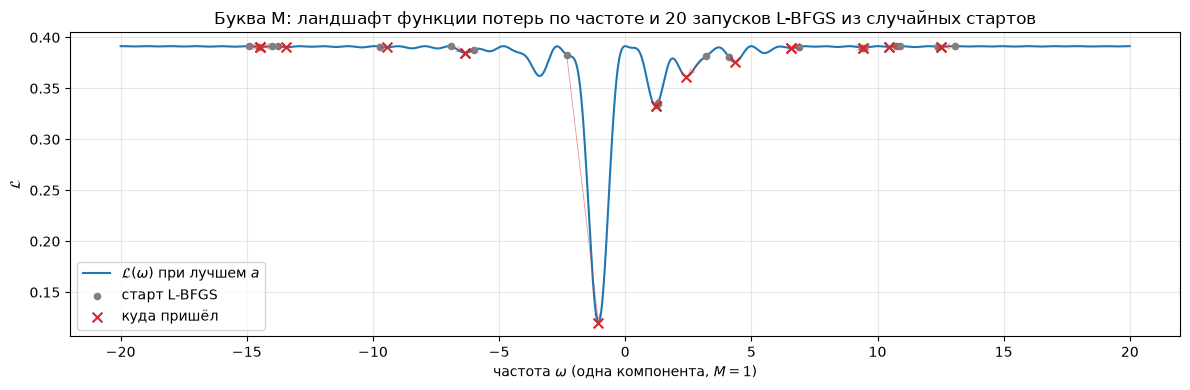

глобальный минимум: w = -1.06, L = 0.120;  без модели L = 0.391
нашли глобальную яму (|w - w_best| < 0.5): 1 из 20


In [126]:
def fit(theta0, t, z, mask=None, maxiter=3000):
    """L-BFGS из точки theta0. Возвращает найденные параметры и потери."""
    res = minimize(loss_and_grad, theta0, args=(t, z, mask), jac=True,
                   method="L-BFGS-B", options={"maxiter": maxiter})
    return res.x, res.fun

def projections(r, t, grid):
    """c_r(w) = 1/N sum_n r_n exp(-2πi w t_n) для всех w из grid."""
    return np.exp(-2j * np.pi * np.outer(grid, t)) @ r / len(r)

omega_plot = np.arange(-20, 20, 0.01)
energy_m = np.mean(np.abs(z_m) ** 2)
L_omega = energy_m - np.abs(projections(z_m, t_grid, omega_plot)) ** 2

rng = np.random.default_rng(0)
starts = rng.uniform(-15, 15, 20)
ends = []
for w0 in starts:
    theta, L = fit(np.array([w0, 0.0, 0.0]) + np.array([0, *rng.normal(0, 0.1, 2)]), t_grid, z_m)
    ends.append((theta[0], L))
ends = np.array(ends)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(omega_plot, L_omega, color="tab:blue", lw=1.5, label=r"$\mathcal{L}(\omega)$ при лучшем $a$")
ax.scatter(starts, energy_m - np.abs(projections(z_m, t_grid, starts)) ** 2,
           color="gray", s=20, zorder=3, label="старт L-BFGS")
ax.scatter(ends[:, 0], ends[:, 1], color="tab:red", marker="x", s=50, zorder=4, label="куда пришёл")
for w0, (w1, L1) in zip(starts, ends):
    ax.annotate("", xy=(w1, L1), xytext=(w0, energy_m - abs(projections(z_m, t_grid, np.array([w0]))[0]) ** 2),
                arrowprops=dict(arrowstyle="->", color="tab:red", lw=0.6, alpha=0.5))
ax.set_xlabel(r"частота $\omega$ (одна компонента, $M = 1$)")
ax.set_ylabel(r"$\mathcal{L}$")
ax.set_title("Буква M: ландшафт функции потерь по частоте и 20 запусков L-BFGS из случайных стартов")
ax.legend(loc="lower left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("figs/landscape.png", dpi=200)
plt.show()

w_best = omega_plot[np.argmin(L_omega)]
print(f"глобальный минимум: w = {w_best:.2f}, L = {L_omega.min():.3f};  без модели L = {energy_m:.3f}")
print("нашли глобальную яму (|w - w_best| < 0.5):", np.sum(np.abs(ends[:, 0] - w_best) < 0.5), "из", len(starts))

**Что видно.**
- Глобальный минимум один — около $\omega \approx -1$ (главный вектор буквы M, обход по часовой). Он не ровно в $-1$, а около $-1.06$: соседние частоты $1$ и $2$ тоже большие, и одна компонента, чуть сдвинувшись, захватывает часть их энергии.
- Яма узкая, ширина около 2. Вокруг почти плоское плато на уровне «без модели» ($\approx 0.39$) с мелкими ямками — ложными минимумами.
- Из 20 случайных стартов глобальную яму нашёл только 1 — того же порядка, что оценка $2/30$ из 7.4. Остальные застряли на плато или в соседних мелких ямах.

Это и есть причина, почему подход 3 из случайной точки ненадёжен.

#### 8.3. Три подхода в коде

- `best_freq_on_grid` — перебор: проекции остатка на все частоты сетки и выбор максимальной по модулю. Это глобальный поиск по одной переменной, поэтому в ложные минимумы он не попадает.
- `greedy(..., refit=False)` — **подход 1**: перебор даёт старт новой компоненты, L-BFGS уточняет только её три параметра (`mask`).
- `greedy(..., refit=True)` — **подход 2**: то же, но уточняются все $3m$ параметров, стартуя с текущих значений (тёплый старт).
- `joint` — **подход 3**: все $3M$ параметров из случайного старта.

In [127]:
omega_grid = np.arange(-40, 40, 0.01)

def best_freq_on_grid(r, t, grid=omega_grid):
    """Частота с максимальной |проекцией| остатка и сама проекция (стартовый коэффициент)."""
    P = projections(r, t, grid)
    j = np.argmax(np.abs(P))
    return grid[j], P[j]

def greedy(t, z, M_max, refit):
    """Подходы 1 (refit=False) и 2 (refit=True). Возвращает ошибки после каждого шага и итоговые частоты."""
    w = np.array([])
    a = np.array([], dtype=complex)
    errs = []
    for m in range(M_max):
        z_hat = np.exp(2j * np.pi * np.outer(t, w)) @ a if m > 0 else 0
        w_new, a_new = best_freq_on_grid(z - z_hat, t)
        w, a = np.append(w, w_new), np.append(a, a_new)
        M = m + 1
        if refit:
            mask = None
        else:
            mask = np.zeros(3 * M)
            mask[[M - 1, 2 * M - 1, 3 * M - 1]] = 1
        theta, L = fit(pack(w, a), t, z, mask)
        w, a = unpack(theta, M)
        errs.append(L)
    return np.array(errs), w

def joint(t, z, M, seed):
    """Подход 3: все 3M параметров из случайного старта."""
    rng = np.random.default_rng(seed)
    theta0 = np.concatenate([rng.uniform(-15, 15, M),
                             rng.normal(0, 0.1, 2 * M)])
    theta, L = fit(theta0, t, z)
    return L

#### 8.4. Прогон и результаты

Для каждой кривой: подходы 1 и 2 при $M = 1..10$, подход 3 — для каждого $M$ по 10 запусков. Для сравнения — ошибка приближения $M$ векторами ДПФ с целыми частотами из раздела 4. Прогон занимает около полуминуты.

In [128]:
M_max_B = 10
seeds = range(10)
resB = {}
for name, z in [("звезда", z_star), ("буква M", z_m)]:
    e1, w1 = greedy(t_grid, z, M_max_B, refit=False)
    e2, w2 = greedy(t_grid, z, M_max_B, refit=True)
    e3 = np.array([[joint(t_grid, z, M, s) for s in seeds] for M in range(1, M_max_B + 1)])
    k, c = dft_coeffs(z)
    order = np.argsort(-np.abs(c))
    e_dft = np.array([np.sum(np.abs(c) ** 2) - np.sum(np.abs(c[order[:M]]) ** 2) for M in range(1, M_max_B + 1)])
    resB[name] = dict(e1=e1, e2=e2, e3=e3, dft=e_dft, w1=w1, w2=w2, energy=np.mean(np.abs(z) ** 2))
    print(name)
    print("  частоты, подход 1:", np.round(w1, 2))
    print("  частоты, подход 2:", np.round(w2, 2))

звезда
  частоты, подход 1: [  1.01  -4.01   5.99 -14.04  16.02  -9.     0.31  11.     1.58 -24.01]
  частоты, подход 2: [  1.    -4.     6.   -13.98  16.02  -8.99  10.98 -24.    26.   -34.01]
буква M
  частоты, подход 1: [-1.06  1.01  3.15 -3.07  2.01 -1.93 -4.21  4.1  -5.91 -4.95]
  частоты, подход 2: [-1.14  0.86  2.95 -2.19  1.94 -2.15 -3.99  4.03 -5.9   5.99]


In [129]:
rows = []
for name, R in resB.items():
    for M in [1, 3, 5, 10]:
        e3 = R["e3"][M - 1]
        rows.append({"кривая": name, "M": M, "подход 1": R["e1"][M - 1], "подход 2": R["e2"][M - 1],
                     "подход 3: лучший": e3.min(), "подход 3: медиана": np.median(e3),
                     "ДПФ (целые)": R["dft"][M - 1], "без модели": R["energy"]})
pd.DataFrame(rows).set_index(["кривая", "M"]).style.format("{:.2e}")

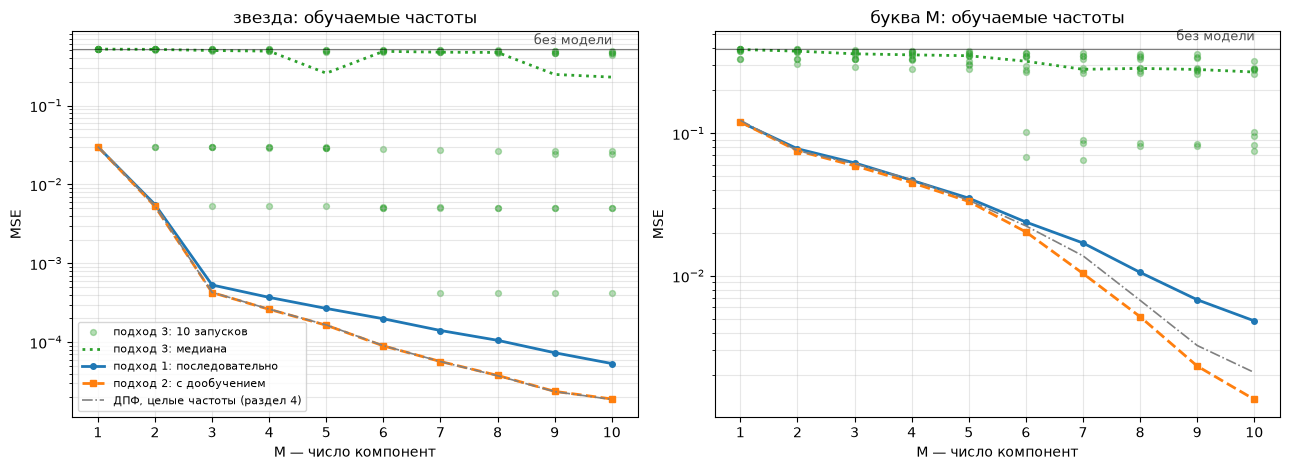

In [130]:
Ms = np.arange(1, M_max_B + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (name, R) in zip(axes, resB.items()):
    for M, e3 in zip(Ms, R["e3"]):
        ax.scatter(np.full(len(e3), M), e3, color="tab:green", alpha=0.35, s=18,
                   label="подход 3: 10 запусков" if M == 1 else None)
    ax.semilogy(Ms, np.median(R["e3"], axis=1), color="tab:green", ls=":", lw=2, label="подход 3: медиана")
    ax.semilogy(Ms, R["e1"], color="tab:blue", lw=2, marker="o", ms=4, label="подход 1: последовательно")
    ax.semilogy(Ms, R["e2"], color="tab:orange", ls="--", lw=2, marker="s", ms=4, label="подход 2: с дообучением")
    ax.semilogy(Ms, R["dft"], color="gray", ls="-.", lw=1.2, label="ДПФ, целые частоты (раздел 4)")
    ax.axhline(R["energy"], color="black", lw=0.8, alpha=0.5)
    ax.text(M_max_B, R["energy"] * 1.15, "без модели", ha="right", fontsize=9, alpha=0.7)
    ax.set_title(f"{name}: обучаемые частоты")
    ax.set_xlabel("M — число компонент"); ax.set_ylabel("MSE")
    ax.set_xticks(Ms); ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig("figs/expB.png", dpi=200)
plt.show()

#### 8.5. Выводы эксперимента B

1. **Подход 3 (всё сразу) ненадёжен.** Медиана ошибки по 10 запускам почти не отличается от «без модели» (звезда: $0.23$–$0.52$ при «без модели» $0.52$; буква M: $0.27$–$0.39$ при $0.39$) — типичный запуск почти ничего не выучил. Даже лучший из 10 запусков хуже жадных подходов на 1–2 порядка (звезда, $M = 10$: $4.2\cdot 10^{-4}$ против $1.9\cdot 10^{-5}$). Причина — невыпуклый ландшафт из 8.2: старт редко попадает в нужную яму.
2. **Подход 2 (с дообучением) — лучший.** У звезды он совпадает с ДПФ по целым частотам и находит почти целые частоты $1, -4, 6, -14, 16, -9, 11, \dots$ — ровно спектр звезды из раздела 4. У буквы M он даже немного лучше ДПФ ($M = 10$: $1.6\cdot 10^{-3}$ против $2.1\cdot 10^{-3}$): нецелые частоты дают больше свободы. Цена — приближение с нецелыми частотами не замкнуто.
3. **Подход 1 (без дообучения) — хуже подхода 2** примерно в 3 раза при $M = 10$. Старые компоненты не исправляются, и новые тратятся на компенсацию их ошибок: у звезды на 7-м и 9-м шагах выбраны частоты $0.31$ и $1.58$, которых в спектре звезды нет, — это «заплатки» возле уже выбранной частоты $1$.
4. **Почему жадный подход работает:** каждую новую частоту он ищет перебором по всей сетке — это глобальный поиск по одной переменной, — а градиентный метод нужен только для уточнения внутри уже найденной ямы (тёплый старт). Подход 3 пытается решить невыпуклую задачу с $3M$ параметрами локальным методом из случайной точки.

**Итог.** При обучаемых частотах задача невыпуклая, и способ подбора становится решающим: «последовательно с дообучением» — надёжно и точно, «последовательно» — дешевле, но хуже, «всё сразу» из случайного старта — почти не работает без мультистарта или хорошей инициализации.

### 9. Другие рисунки: галерея контуров

**Зачем этот раздел.** Звезда и буква M — две кривые, и обе из отрезков. Проверим, что выводы не случайны: возьмём шесть разных замкнутых контуров — гладкие и угловатые, простые и сложные — и прогоним на них всё сразу: приближение $M$ векторами, скорость убывания коэффициентов и три подхода с обучаемыми частотами.

**Данные.** Силуэты-иконки из открытых наборов: рыба, киви, лошадь, ворона — Font Awesome Free (лицензия CC BY 4.0, © Fonticons, Inc.); самолёт и молния — Bootstrap Icons (лицензия MIT). Файлы лежат в `example/`.

У многих иконок несколько контуров: например, у рыбы отдельным контуром вырезан глаз. Берём самый длинный — внешний силуэт. Функция `load_svg_contour` делает это через `continuous_subpaths()` и проверяет, что контур замкнут.

In [131]:
from svgpathtools import svg2paths

def load_svg_contour(filename, n_per_seg=50):
    """Самый длинный замкнутый контур в SVG как комплексный массив (ось y вверх)."""
    paths, _ = svg2paths(filename)
    subpaths = [sp for p in paths for sp in p.continuous_subpaths()]
    contour = max(subpaths, key=lambda sp: sp.length())
    assert contour.isclosed(), f"{filename}: контур не замкнут"
    T = np.linspace(0, 1, n_per_seg, endpoint=False)
    pts = [seg.point(t) for seg in contour for t in T]
    return np.conj(np.array(pts))

gallery_files = {
    "рыба":    "example/fish.svg",
    "киви":    "example/kiwi-bird.svg",
    "лошадь":  "example/horse.svg",
    "ворона":  "example/crow.svg",
    "самолёт": "example/airplane.svg",
    "молния":  "example/lightning.svg",
}
gallery = {name: normalize(resample_arclength(load_svg_contour(f), N)) for name, f in gallery_files.items()}

#### 9.1. Приближение $M$ векторами

Для каждого рисунка — приближения 5, 15 и 50 векторами ДПФ (как в разделе 4). В заголовке — относительная ошибка.

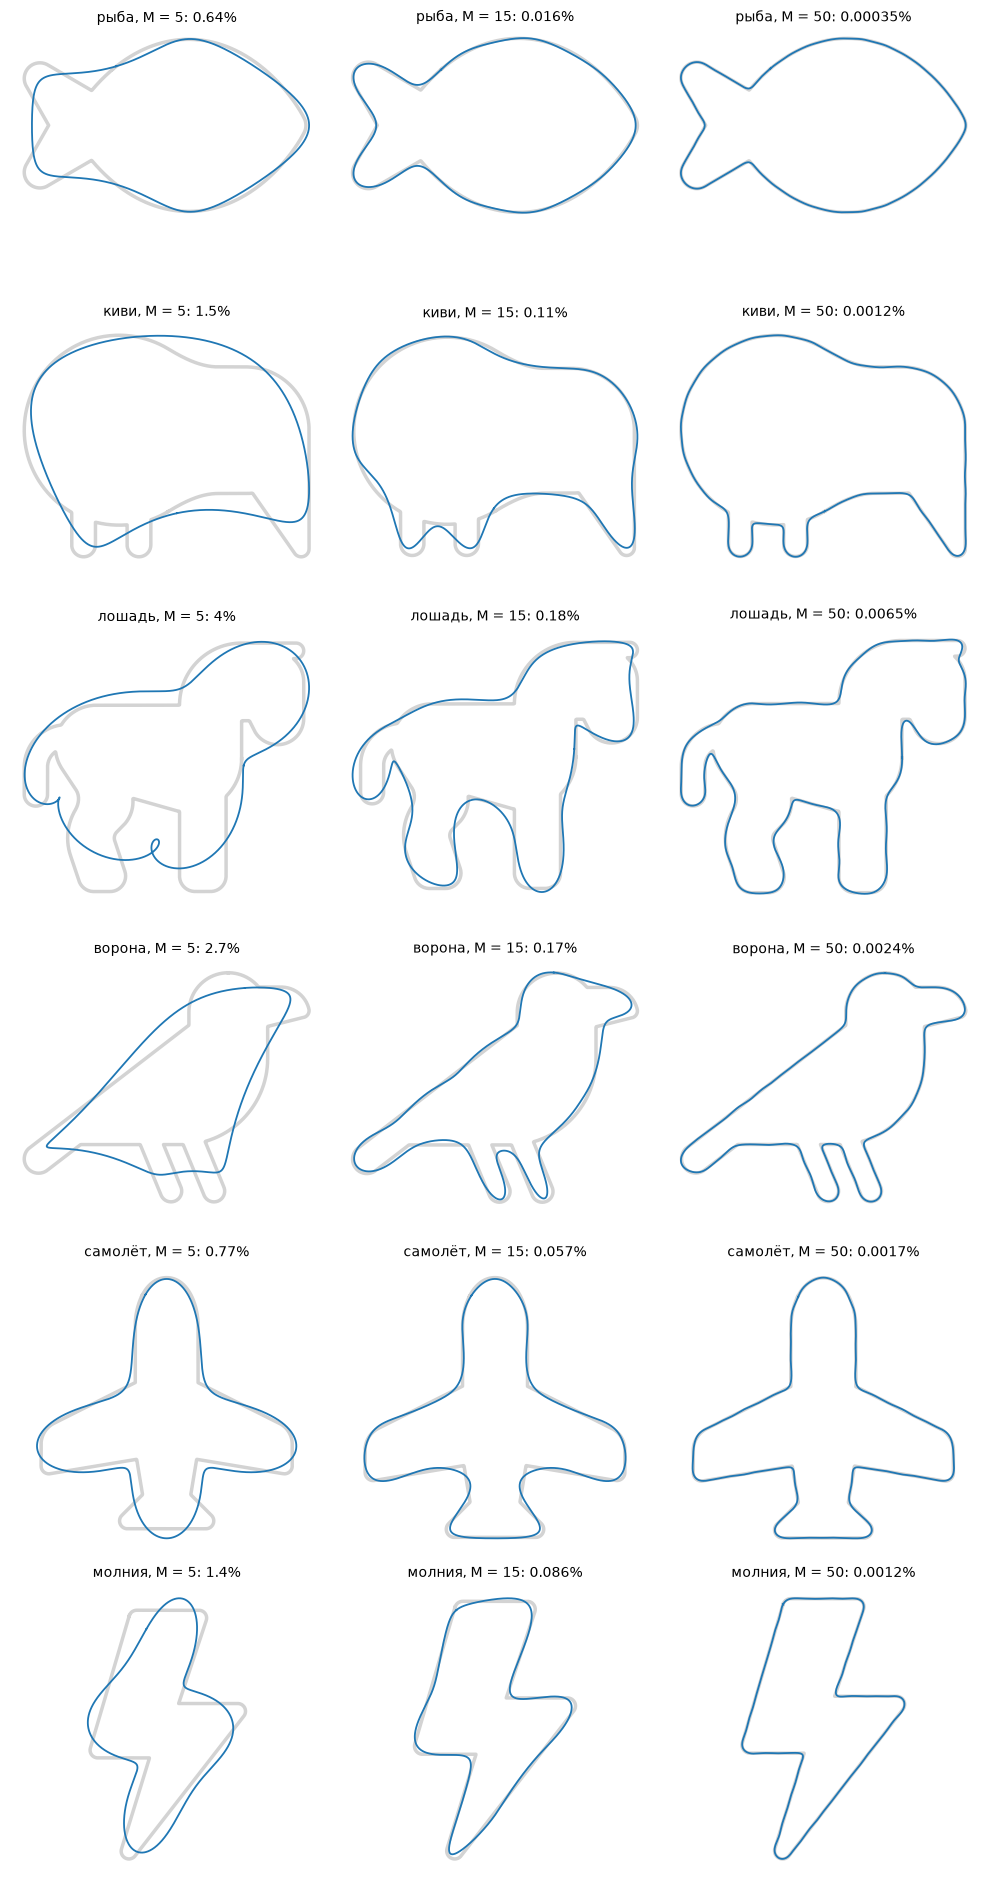

In [132]:
Ms_gal = [5, 15, 50]
t_fine = np.linspace(0, 1, 3000)
fig, axes = plt.subplots(len(gallery), len(Ms_gal), figsize=(10, 3.2 * len(gallery)))
for row, (name, z) in enumerate(gallery.items()):
    k, c = dft_coeffs(z)
    energy = np.mean(np.abs(z) ** 2)
    z_closed = np.append(z, z[0])
    for col, M in enumerate(Ms_gal):
        ax = axes[row, col]
        fr, co = top_m(k, c, M)
        rel = mse(z, evaluate(co, fr, t_grid)) / energy
        z_hat = evaluate(co, fr, t_fine)
        ax.plot(z_closed.real, z_closed.imag, color="lightgray", lw=2.5)
        ax.plot(z_hat.real, z_hat.imag, color="tab:blue", lw=1.3)
        ax.set_title(f"{name}, M = {M}: {100 * rel:.2g}%", fontsize=10)
        ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.savefig("figs/gallery.png", dpi=200)
plt.show()

#### 9.2. Сводная таблица

Для каждого рисунка:
- сколько векторов нужно для относительной ошибки 1% и 0.1%;
- наклон убывания $|c_k|$ в log-log (по $|k|$ от 10 до 250);
- три главные частоты;
- ошибки при $M = 10$: ДПФ с целыми частотами, подходы 1 и 2, подход 3 (лучший и медиана из 10 запусков) и уровень «без модели».

In [133]:
def decay_slope(k, c, kmin=10, kmax=250):
    """Наклон log|c_k| от log|k| на хвосте: |c_k| ~ k^slope."""
    amp = np.zeros(kmax + 1)
    for kv, cv in zip(k, c):
        if 0 < abs(kv) <= kmax:
            amp[abs(kv)] = max(amp[abs(kv)], abs(cv))
    kk = np.arange(kmin, kmax + 1)
    return np.polyfit(np.log(kk), np.log(amp[kmin:] + 1e-20), 1)[0]

M_cmp = 10
rows = []
for name, z in gallery.items():
    k, c = dft_coeffs(z)
    order = np.argsort(-np.abs(c))
    total = np.sum(np.abs(c) ** 2)
    rel = 1 - np.cumsum(np.abs(c[order]) ** 2) / total
    e1, _ = greedy(t_grid, z, M_cmp, refit=False)
    e2, _ = greedy(t_grid, z, M_cmp, refit=True)
    e3 = [joint(t_grid, z, M_cmp, s) for s in range(10)]
    rows.append({
        "рисунок": name,
        "M для 1%": int(np.argmax(rel < 1e-2)) + 1,
        "M для 0.1%": int(np.argmax(rel < 1e-3)) + 1,
        "наклон": round(decay_slope(k, c), 2),
        "главные k": k[order[:3]].tolist(),
        f"ДПФ, M={M_cmp}": total - np.sum(np.abs(c[order[:M_cmp]]) ** 2),
        "подход 1": e1[-1],
        "подход 2": e2[-1],
        "подход 3: лучший": min(e3),
        "подход 3: медиана": np.median(e3),
        "без модели": np.mean(np.abs(z) ** 2),
    })
gal_table = pd.DataFrame(rows).set_index("рисунок")
float_cols = [col for col in gal_table.columns if gal_table[col].dtype == float and col != "наклон"]
gal_table.style.format({col: "{:.2e}" for col in float_cols})

,M для 1%,M для 0.1%,наклон,главные k,"ДПФ, M=10",подход 1,подход 2,подход 3: лучший,подход 3: медиана,без модели
рисунок,,,,,,,,,,
рыба,5,11,-2.010000,"[-1, 1, -2]",6.92e-04,8.98e-04,4.37e-04,5.74e-03,2.23e-01,5.09e-01
киви,7,16,-2.120000,"[1, 2, -1]",1.74e-03,2.46e-03,1.16e-03,1.83e-02,2.55e-01,5.53e-01
лошадь,9,18,-2.150000,"[1, -1, 2]",2.10e-03,2.95e-03,1.78e-03,1.11e-02,1.63e-01,3.73e-01
ворона,11,17,-2.090000,"[1, -2, -1]",4.02e-03,3.34e-03,1.53e-03,2.42e-02,1.64e-01,3.98e-01
самолёт,5,11,-2.160000,"[-1, 3, -5]",5.34e-04,8.35e-04,3.47e-04,6.58e-03,1.86e-01,4.33e-01
молния,6,15,-2.300000,"[-1, 1, -3]",7.42e-04,7.84e-04,6.45e-04,3.79e-02,2.79e-01,3.83e-01


#### 9.3. Анимация эпициклов (бонус)

Цепочка из 30 векторов рисует лошадь: на каждом кадре векторы повёрнуты на свой угол, синим — уже нарисованный след. GIF сохраняется в `figs/epicycles.gif` (около 10 секунд). Можно поменять `name_gif` на любой рисунок из галереи или `M_gif` на другое число векторов.

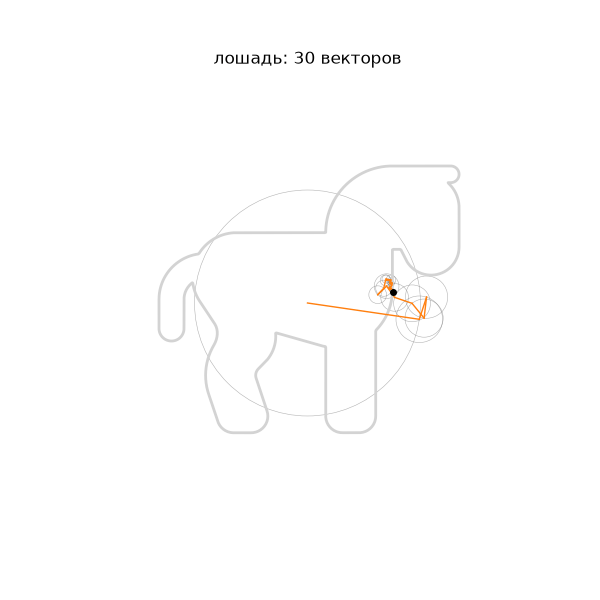

In [134]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

name_gif, M_gif, frames = "лошадь", 30, 120
z = gallery[name_gif]
k, c = dft_coeffs(z)
fr, co = top_m(k, c, M_gif)
t_frames = np.linspace(0, 1, frames, endpoint=False)
trace = evaluate(co, fr, t_frames)

fig, ax = plt.subplots(figsize=(6, 6))
z_closed = np.append(z, z[0])

def draw(i):
    ax.clear()
    ax.plot(z_closed.real, z_closed.imag, color="lightgray", lw=2)
    p = 0j
    for cc, kk in zip(co, fr):
        v = cc * np.exp(2j * np.pi * kk * t_frames[i])
        ax.add_patch(plt.Circle((p.real, p.imag), abs(cc), fill=False, color="gray", lw=0.4, alpha=0.6))
        ax.plot([p.real, (p + v).real], [p.imag, (p + v).imag], color="tab:orange", lw=1)
        p += v
    ax.plot(trace[:i + 1].real, trace[:i + 1].imag, color="tab:blue", lw=2)
    ax.plot(p.real, p.imag, "o", color="black", ms=4)
    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(f"{name_gif}: {M_gif} векторов")

anim = FuncAnimation(fig, draw, frames=frames)
anim.save("figs/epicycles.gif", writer=PillowWriter(fps=20))
plt.close(fig)
Image(filename="figs/epicycles.gif")

#### 9.4. Выводы по галерее

1. **Скорость убывания одинакова: наклон от $-2.0$ до $-2.3$** у всех шести рисунков. У всех силуэтов есть углы, поэтому $|c_k| \sim 1/k^2$, как предсказывает интегрирование по частям: результат не зависит от того, гладкий рисунок «в целом» или нет, хвост спектра определяется изломами.
2. **Узнаваемый рисунок — за 5–11 векторов** (ошибка 1%), точный — за 11–18 (0.1%). Больше всего нужно лошади и вороне: у них тонкие ноги и клюв — мелкие детали, которые живут на больших частотах.
3. **Главная частота — $\pm 1$**: первый вектор рисует «окружность» силуэта, знак показывает направление обхода в файле.
4. **Три подхода при $M = 10$ ведут себя одинаково на всех рисунках** — так же, как на звезде и букве M:
   - подход 2 лучший и на всех шести рисунках лучше ДПФ с целыми частотами (нецелые частоты дают больше свободы, ценой незамкнутости приближения);
   - подход 1 хуже подхода 2 и почти везде хуже ДПФ;
   - подход 3: даже лучший из 10 запусков хуже подхода 2 в 10–60 раз, медиана — 40–70% от уровня «без модели».

Выводы разделов 6–8 подтверждаются на разных по форме рисунках.

#### 9.5. Сложный рисунок: профиль-портрет

Контур посложнее: силуэт головы в профиль с хвостом волос, шеей и плечами (`example/portrait.svg`, нарисован для этой работы). Здесь есть и крупные формы (голова, плечи), и мелкие детали (нос, губы, подбородок) — хорошо видно, как ряд Фурье «проявляет» детали с ростом $M$.

Две анимации:
- `make_growing_gif` — приближение $M$ векторами при растущем $M$, от 1 до 100: рисунок постепенно проявляется;
- `make_epicycles_gif` — цепочка из $M$ векторов рисует контур; мелкие круги (радиус меньше 0.01) не рисуются, чтобы не было каши.

In [ ]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image

def make_epicycles_gif(z, M, filename, frames=150, fps=25, title=""):
    """GIF: цепочка из M векторов (по убыванию |c_k|) рисует приближение кривой z."""
    k, c = dft_coeffs(z)
    fr, co = top_m(k, c, M)
    t_frames = np.linspace(0, 1, frames, endpoint=False)
    trace = evaluate(co, fr, t_frames)
    z_closed = np.append(z, z[0])
    lim = 1.1 * np.max(np.abs(z))

    fig, ax = plt.subplots(figsize=(6, 6))
    def draw(i):
        ax.clear()
        ax.plot(z_closed.real, z_closed.imag, color="0.85", lw=3)
        p = 0j
        for cc, kk in zip(co, fr):
            v = cc * np.exp(2j * np.pi * kk * t_frames[i])
            if abs(cc) > 0.01:
                ax.add_patch(plt.Circle((p.real, p.imag), abs(cc), fill=False, color="gray", lw=0.4, alpha=0.5))
            ax.plot([p.real, (p + v).real], [p.imag, (p + v).imag], color="tab:orange", lw=0.9)
            p += v
        ax.plot(trace[:i + 1].real, trace[:i + 1].imag, color="tab:blue", lw=2)
        ax.plot(p.real, p.imag, "o", color="black", ms=4)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        ax.set_aspect("equal"); ax.axis("off")
        ax.set_title(title or f"{M} векторов")
    anim = FuncAnimation(fig, draw, frames=frames)
    anim.save(filename, writer=PillowWriter(fps=fps))
    plt.close(fig)

def make_growing_gif(z, Ms, filename, fps=4, title=""):
    """GIF: приближение M векторами при растущем M — рисунок «проявляется»."""
    k, c = dft_coeffs(z)
    energy = np.mean(np.abs(z) ** 2)
    t_fine = np.linspace(0, 1, 3000)
    t_grid = np.arange(len(z)) / len(z)
    z_closed = np.append(z, z[0])
    lim = 1.1 * np.max(np.abs(z))
    fig, ax = plt.subplots(figsize=(6, 6))
    def draw(i):
        M = Ms[i]
        fr, co = top_m(k, c, M)
        rel = mse(z, evaluate(co, fr, t_grid)) / energy
        z_hat = evaluate(co, fr, t_fine)
        ax.clear()
        ax.plot(z_closed.real, z_closed.imag, color="0.85", lw=3)
        ax.plot(z_hat.real, z_hat.imag, color="tab:blue", lw=1.8)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
        ax.set_aspect("equal"); ax.axis("off")
        ax.set_title(f"{title}M = {M}, ошибка {100 * rel:.2g}%")
    anim = FuncAnimation(fig, draw, frames=len(Ms))
    anim.save(filename, writer=PillowWriter(fps=fps))
    plt.close(fig)

относительная ошибка < 1e-02: M = 8
относительная ошибка < 1e-03: M = 16
относительная ошибка < 1e-04: M = 33


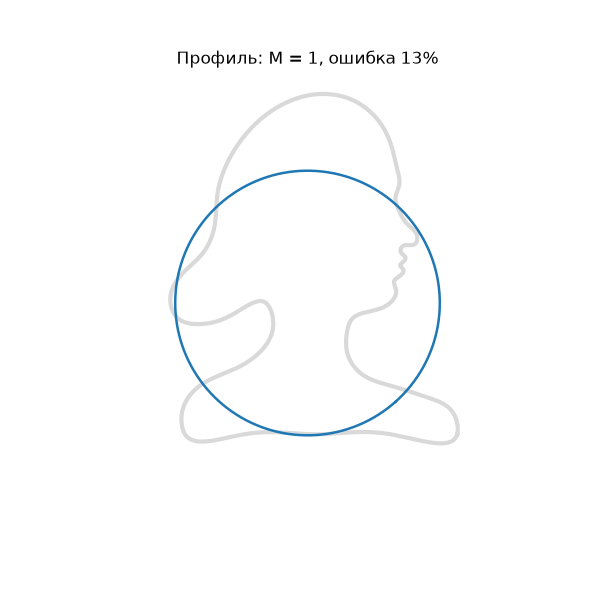

In [136]:
z_portrait = normalize(resample_arclength(load_svg_contour("example/portrait.svg", n_per_seg=1), N))

k_p, c_p = dft_coeffs(z_portrait)
rel_p = 1 - np.cumsum(np.sort(np.abs(c_p))[::-1] ** 2) / np.sum(np.abs(c_p) ** 2)
for level in [1e-2, 1e-3, 1e-4]:
    print(f"относительная ошибка < {level:.0e}: M = {np.argmax(rel_p < level) + 1}")

make_growing_gif(z_portrait, [1, 2, 3, 4, 5, 6, 8, 10, 13, 16, 20, 25, 30, 40, 50, 70, 100],
                 "figs/portrait_growing.gif", title="Профиль: ")
Image(filename="figs/portrait_growing.gif")

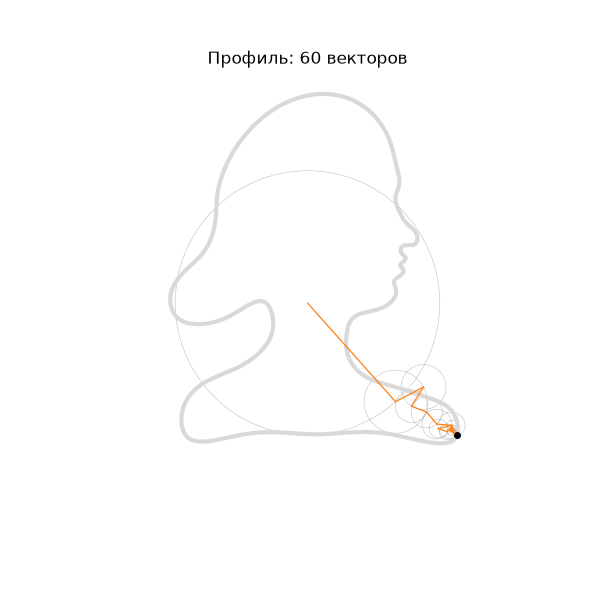

In [ ]:
make_epicycles_gif(z_portrait, 60, "figs/portrait_epicycles.gif", title="Профиль: 60 векторов")
Image(filename="figs/portrait_epicycles.gif")

**Что видно.**
- Относительная ошибка 1% достигается уже при $M = 8$, но на этом кадре **лица нет**: нос, губы и подбородок сглажены в одну дугу. MSE считает всю кривую сразу, а мелкие детали занимают малую долю её длины и почти не влияют на среднюю ошибку. Малая MSE не равна «похоже на глаз».
- Профиль лица проявляется к $M \approx 25$–$30$ (ошибка около 0.01%), а при $M = 60$–$100$ приближение почти неотличимо от оригинала.
- Это иллюстрация скорости убывания из 9.4: мелкие детали «живут» на больших частотах, поэтому появляются последними.

#### 9.6. Фигуры из учебника и распознавание по дескрипторам Фурье

**Источник.** Фигуры взяты с рисунка 6.17 главы 6 «Contours» учебника R. Jain, R. Kasturi, B. G. Schunck, *Machine Vision* (McGraw-Hill, 1995): [MachineVision_Chapter6.pdf](https://cse.usf.edu/~r1k/MachineVisionBook/MachineVision.files/MachineVision_Chapter6.pdf). Подпись к рисунку: (a) четыре эталонных бинарных объекта; (b) их масштабированные версии; (c) масштабированные и повёрнутые версии. Картинка сохранена в `example/jain_fig6_17.png`.

Рисунок относится к задаче 6.5 этой главы: подобрать представление контура, по которому можно узнать фигуру независимо от её масштаба и поворота. Это естественное продолжение нашей работы: попробуем решить эту задачу с помощью коэффициентов Фурье.

**Извлечение контуров.** Картинка растровая, поэтому контуры получаем как линию уровня 0.5 бинарной маски (`plt.contour`): чёрное — 1, белое — 0. Короткие контуры (подписи «(a)», «(b)», «(c)», шум) отбрасываем по длине. Все контуры разворачиваем в обход против часовой стрелки — по знаку площади.

In [ ]:
def extract_contours(filename, min_length=500):
    """Внешние контуры чёрных фигур на картинке: список комплексных массивов (обход против часовой)."""
    img = plt.imread(filename)
    gray = img[..., :3].mean(axis=2) if img.ndim == 3 else img
    mask = np.pad((gray < 0.5).astype(float), 2)
    fig = plt.figure()
    cs = plt.contour(mask, levels=[0.5])
    plt.close(fig)
    segs = [s for s in cs.allsegs[0]
            if np.sum(np.hypot(*np.diff(s, axis=0).T)) > min_length]
    contours = []
    for s in segs:
        z = s[:-1, 0] - 1j * s[:-1, 1]
        area = 0.5 * np.sum(z.real * np.roll(z.imag, -1) - np.roll(z.real, -1) * z.imag)
        if area < 0:
            z = z[::-1]
        contours.append(z)
    return contours

contours = extract_contours("example/jain_fig6_17.png")

contours.sort(key=lambda z: -z.imag.mean())
contours = [z for i in range(0, len(contours), 2) for z in sorted(contours[i:i + 2], key=lambda z: z.real.mean())]
shape_names = ["клевер", "трефа", "бык", "самолёт",
               "самолёт", "бык", "трефа", "клевер",
               "клевер", "трефа", "бык", "самолёт"]
shape_sets = ["a"] * 4 + ["b"] * 4 + ["c"] * 4
jain = [normalize(resample_arclength(z, N)) for z in contours]
print("найдено контуров:", len(jain))

найдено контуров: 12


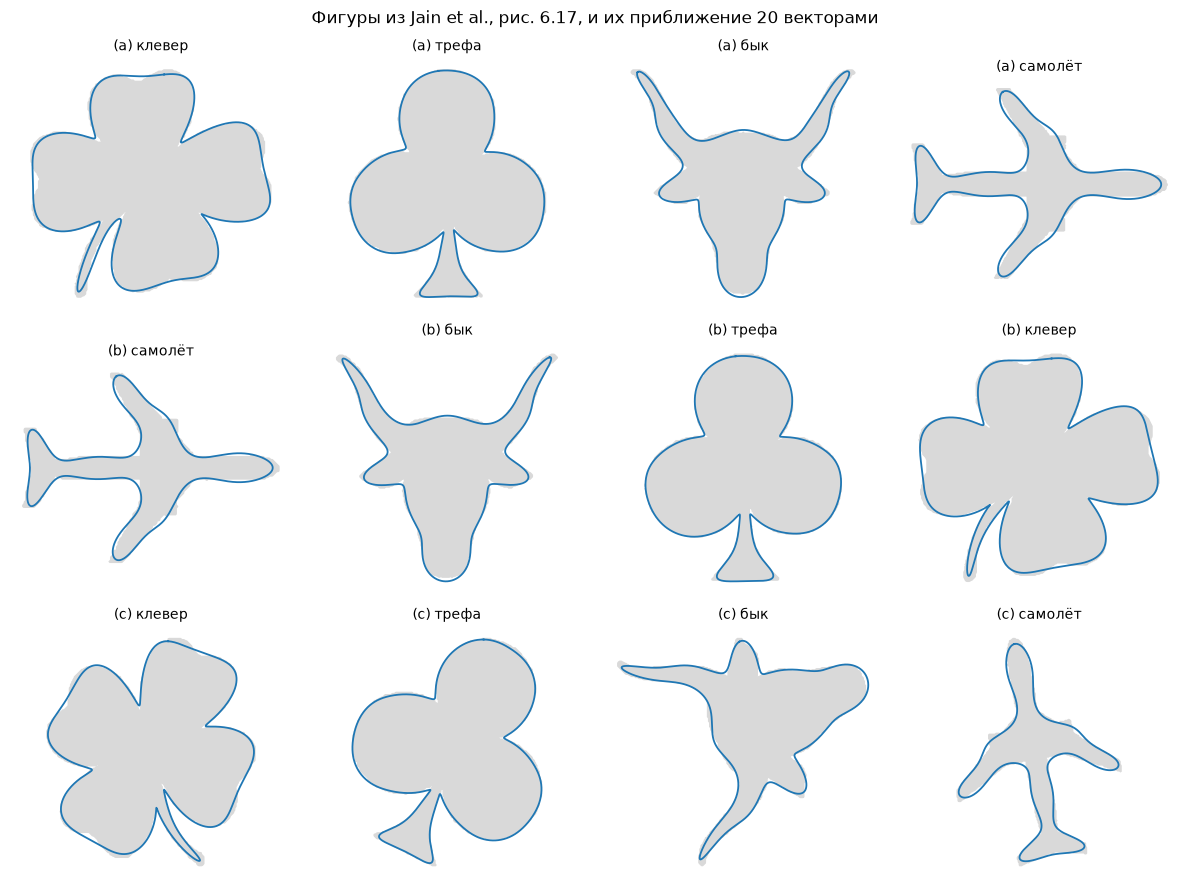

In [139]:
M_show = 20
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, z, name, st in zip(axes.flat, jain, shape_names, shape_sets):
    k, c = dft_coeffs(z)
    fr, co = top_m(k, c, M_show)
    z_hat = evaluate(co, fr, np.linspace(0, 1, 3000))
    z_closed = np.append(z, z[0])
    ax.fill(z_closed.real, z_closed.imag, color="0.85")
    ax.plot(z_hat.real, z_hat.imag, color="tab:blue", lw=1.3)
    ax.set_title(f"({st}) {name}", fontsize=10)
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle(f"Фигуры из Jain et al., рис. 6.17, и их приближение {M_show} векторами")
plt.tight_layout()
plt.savefig("figs/jain_shapes.png", dpi=200)
plt.show()

**Почему коэффициенты Фурье подходят для распознавания.** Посмотрим, как меняются $c_k$ при простых преобразованиях кривой:

| преобразование кривой | что происходит с коэффициентами |
|---|---|
| сдвиг $z(t) + b$ | меняется только $c_0$ |
| масштаб $s\,z(t)$, $s > 0$ | все $c_k$ умножаются на $s$ |
| поворот $e^{i\varphi} z(t)$ | все $c_k$ умножаются на $e^{i\varphi}$ |
| другая стартовая точка $z(t + \tau)$ | $c_k$ умножается на $e^{2\pi i k\tau}$ |

Последняя строка — замена переменной в интеграле для $c_k$, как в доказательстве симметрии. Во всех случаях, кроме сдвига, у $c_k$ меняется только **фаза** или общий множитель. Поэтому вектор модулей
$$d = \frac{\big(|c_k|\big)_{k = \pm 1, \dots, \pm K}}{\big\|\big(|c_k|\big)\big\|}$$
не зависит ни от положения, ни от масштаба, ни от поворота, ни от того, с какой точки начат обход. Это и есть **дескриптор Фурье** контура. (Направление обхода меняет $k \to -k$, поэтому все контуры мы заранее развернули против часовой.)

Распознаём просто: для фигуры из (b) или (c) ищем эталон из (a) с ближайшим дескриптором, $K = 20$.

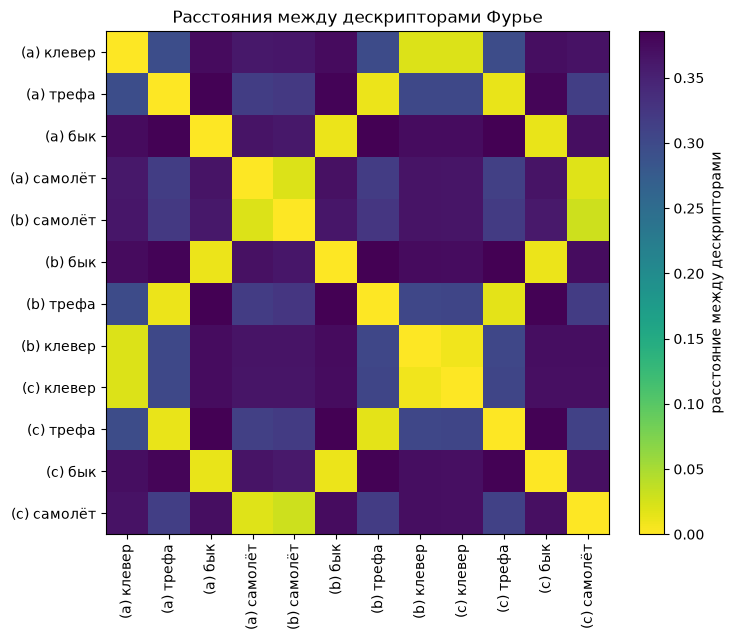

(b) самолёт    -> ближайший эталон: самолёт  (расстояние 0.020)  верно
(b) бык        -> ближайший эталон: бык      (расстояние 0.011)  верно
(b) трефа      -> ближайший эталон: трефа    (расстояние 0.011)  верно
(b) клевер     -> ближайший эталон: клевер   (расстояние 0.020)  верно
(c) клевер     -> ближайший эталон: клевер   (расстояние 0.021)  верно
(c) трефа      -> ближайший эталон: трефа    (расстояние 0.012)  верно
(c) бык        -> ближайший эталон: бык      (расстояние 0.013)  верно
(c) самолёт    -> ближайший эталон: самолёт  (расстояние 0.018)  верно

распознано верно: 8 из 8
одинаковые фигуры: расстояние 0.008–0.030;  разные: 0.295–0.386


In [ ]:
def fourier_descriptor(z, K=20):
    """|c_k| для k = ±1..±K, нормированные на длину вектора: не зависят от сдвига, масштаба, поворота и стартовой точки."""
    k, c = dft_coeffs(z)
    d = np.array([np.abs(c[k == kk][0]) for kk in range(-K, K + 1) if kk != 0])
    return d / np.linalg.norm(d)

desc = np.array([fourier_descriptor(z) for z in jain])
dist = np.linalg.norm(desc[:, None, :] - desc[None, :, :], axis=2)

labels = [f"({s}) {n}" for s, n in zip(shape_sets, shape_names)]
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(dist, cmap="viridis_r")
ax.set_xticks(range(12)); ax.set_xticklabels(labels, rotation=90)
ax.set_yticks(range(12)); ax.set_yticklabels(labels)
fig.colorbar(im, ax=ax, fraction=0.046, label="расстояние между дескрипторами")
ax.set_title("Расстояния между дескрипторами Фурье")
plt.tight_layout()
plt.savefig("figs/jain_distances.png", dpi=200)
plt.show()

refs = range(4)
correct = 0
for i in range(4, 12):
    j = min(refs, key=lambda r: dist[i, r])
    ok = shape_names[j] == shape_names[i]
    correct += ok
    print(f"{labels[i]:14s} -> ближайший эталон: {shape_names[j]:8s} (расстояние {dist[i, j]:.3f})  {'верно' if ok else 'ОШИБКА'}")
same = [dist[i, j] for i in range(12) for j in range(i + 1, 12) if shape_names[i] == shape_names[j]]
diff = [dist[i, j] for i in range(12) for j in range(i + 1, 12) if shape_names[i] != shape_names[j]]
print(f"\nраспознано верно: {correct} из 8")
print(f"одинаковые фигуры: расстояние {min(same):.3f}–{max(same):.3f};  разные: {min(diff):.3f}–{max(diff):.3f}")

**Выводы.**
- Все 8 фигур из (b) и (c) распознаны правильно.
- Расстояние между дескрипторами одной и той же фигуры — $0.008$–$0.03$, между разными фигурами — $0.30$–$0.39$: разрыв в 10 раз, ошибиться трудно. На карте расстояний это светлые клетки на местах одинаковых фигур.
- Небольшие ненулевые расстояния между копиями одной фигуры — от растра: при уменьшении и повороте контур на пикселях искажается.
- Это та же идея, что в разделе 4, только применённая наоборот: там мы по коэффициентам строили кривую, здесь по их модулям узнаём фигуру. Дескрипторы Фурье — классический способ описания контуров в компьютерном зрении (Kuhl, Giardina, 1982).

### 10. Выводы

1. **Представление.** Замкнутую кривую удобно записать как комплексную функцию $z(t)$; её ряд Фурье — это сумма вращающихся векторов (эпициклов). На равномерной по длине сетке коэффициенты даёт ДПФ. Узнаваемый рисунок получается из 5–30 векторов; из-за углов коэффициенты убывают как $1/k^2$, а симметрия делает спектр разреженным (у звезды ненулевые только $k \equiv 1 \pmod 5$).
   Модули $|c_k|$ не зависят от сдвига, масштаба, поворота и стартовой точки, поэтому по ним можно распознавать фигуры: все 8 фигур из учебника Jain et al. (раздел 9.6) узнаны правильно.
2. **Целые частоты, равномерная сетка: три подхода совпадают.** Гармоники ортогональны, поэтому МНК по любому набору частот даёт коэффициенты ДПФ и они не зависят друг от друга; по Парсевалю ошибка — сумма выброшенных $|c_k|^2$. Отсюда последовательный подбор, подбор с дообучением и выбор всех сразу дают одно и то же приближение, и оно оптимально (теорема 5.4, эксперимент A).
3. **Неравномерная сетка: ортогональность ломается, подходы расходятся.** Дообучение (OMP) стабильно лучше последовательного подбора без дообучения (MP), а выбор всего набора сразу по проекциям может проиграть обоим на порядок — он набирает «дублёров» соседних частот. Честный выбор лучшего набора — комбинаторная задача ($\sim 10^{14}$ вариантов уже при $M = 10$).
4. **Обучаемые частоты: задача невыпуклая.** По частоте функция потерь — это узкие ямы шириной около 2 вокруг настоящих частот и плато с ложными минимумами (ядро Дирихле). Обучение всех параметров сразу из случайного старта почти всегда застревает: медиана ошибки близка к «ничего не выучено». Последовательный подбор с дообучением — самый точный и надёжный: перебор по сетке — глобальный поиск по одной частоте, а дообучение — тёплый старт для локального метода. Без дообучения ошибка в 2–3 раза больше. Это подтверждается на всех восьми рисунках.
5. **Что выбирать.**
   - Точки равномерны, частоты целые → просто взять $M$ наибольших коэффициентов ДПФ: быстро и оптимально.
   - Точки неравномерны или частоты обучаемые → последовательный подбор **с дообучением** (OMP или жадный перебор + L-BFGS по всем параметрам).
   - Обучать всё сразу — только с хорошей инициализацией (например, частотами из ДПФ) или с многими случайными стартами.